# RAVDESS Facial Landmark Tracking - Dataset loading code

Sample code developed by Marco Simões (msimoes@dei.uc.pt) in the scope of the Feature Engineering course of the Bachelor in Data Science and Enginnering of Department of Informatics Engineering of the University of Coimbra, Portugal (LECD | DEI-FCTUC). All rights reserved.

No módulo A as perguntas 2.1,2.2,2.3 e 2.4 já estão englobadas no código facultado pelo professor da cadeira

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import random
import sys
from scipy.spatial.distance import cdist
from sklearn.cluster import DBSCAN
from scipy.stats import shapiro, kstest
from scipy.stats import f_oneway
from scipy.stats import kruskal
from sklearn.decomposition import PCA
from sklearn.model_selection import LeaveOneOut
from tqdm import tqdm
from scipy.fft import fft,ifft,fftfreq,rfft,rfftfreq,irfft
from scipy.signal import stft
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, precision_score, f1_score


import warnings
warnings.filterwarnings('ignore')

In [3]:
datapath = 'FacialTracking_Actors_01-24'
nlandmarks = 68


def preprareData(files):
    ''' Load data from csv files and save in numpy arrays '''

    # prepare auxiliar arrays
    actors = np.zeros((len(files)), dtype=np.uint8)
    emotions = np.zeros((len(files)), dtype=np.uint8)
    frames = np.zeros((len(files)), dtype=np.uint16)

    all_data = []


    for i in range(len(files)):
        # process video file
        filename = files[i]
        
        # read csv file
        dataset = pd.read_csv(datapath + '/' + filename, sep=',')
        all_data.append(np.array(dataset.loc[:, 'x_0':'y_'+str(nlandmarks-1)]))
        
        # split filename to get aux values
        parts = filename[:-4].split('-')
        actors[i] = int(parts[-1])
        emotions[i] = int(parts[2])     
        frames[i] = len(dataset.index)

    # create 3d array
    data = np.empty(shape=(len(files), nlandmarks*2, int(np.max(frames))), dtype=np.float32)
    data[:] = np.nan

    # fill the data array
    for i in range(len(files)):
        data[i, :, :int(frames[i])] = all_data[i].T

    return (data, actors, emotions, frames)



# list files in folder 
files = os.listdir(datapath)

# load data
data, actors, emotions, frames = preprareData(files)


# save data
np.save('data.npy', data)
np.save('actors.npy', actors)
np.save('emotions.npy', emotions)
np.save('frames.npy', frames)

In [4]:
print(data)
print(actors)
print(emotions)
print(frames)

[[[490.2 490.2 490.4 ...   nan   nan   nan]
  [488.8 488.8 488.8 ...   nan   nan   nan]
  [489.9 489.9 490.2 ...   nan   nan   nan]
  ...
  [448.5 448.1 448.3 ...   nan   nan   nan]
  [449.4 448.9 449.  ...   nan   nan   nan]
  [447.2 446.5 446.4 ...   nan   nan   nan]]

 [[466.4 466.5 467.  ...   nan   nan   nan]
  [470.4 470.5 470.9 ...   nan   nan   nan]
  [478.3 478.2 478.6 ...   nan   nan   nan]
  ...
  [501.2 501.2 501.6 ...   nan   nan   nan]
  [502.7 502.8 503.2 ...   nan   nan   nan]
  [501.6 501.7 502.1 ...   nan   nan   nan]]

 [[490.6 491.1 491.  ...   nan   nan   nan]
  [490.4 491.  490.9 ...   nan   nan   nan]
  [494.6 495.1 495.1 ...   nan   nan   nan]
  ...
  [509.7 509.5 509.2 ...   nan   nan   nan]
  [510.9 510.6 510.3 ...   nan   nan   nan]
  [507.9 507.5 507.3 ...   nan   nan   nan]]

 ...

 [[481.9 481.1 480.8 ...   nan   nan   nan]
  [482.1 481.2 480.7 ...   nan   nan   nan]
  [486.4 485.3 484.8 ...   nan   nan   nan]
  ...
  [481.5 482.1 482.2 ...   nan   nan   n

In [5]:
def reshapeData(data3d, emotions, actors, frames):
    ''' Convert 3d array into 2d without NaNs '''

    # prepare arrays of data, emotions and actors of shape (n, 136), (n,) and (n,) [being n the sum of all frames]
    data2d = np.empty(shape=(np.sum(frames), data.shape[1]), dtype=np.float32)
    emotions_by_frame = np.empty(shape=(np.sum(frames)), dtype=np.uint8)
    actor_by_frame = np.empty(shape=(np.sum(frames)), dtype=np.uint8)

    k = 0
    for v in range(data3d.shape[0]):
        # gets non nan values of video v
        data2d[k:k+frames[v], :] = data3d[v, :, :frames[v]].T
        
        # fills emotions and actors arrays
        emotions_by_frame[k:k+frames[v]] = emotions[v]
        actor_by_frame[k:k+frames[v]] = actors[v]
        
        # updates k 
        k += frames[v]

    return (data2d, emotions_by_frame, actor_by_frame)


def getData(actor=None, emotion=None, type='2d'):
    ''' Returns data in 2d or 3d shape. if actor is provided, filters data to return that actor. 
    if emotion is provided, filters data to return only that emotion. Cumulative filters, meaning that 
    if both are provided, the intersection of both filters is returned (only videos of that actor with that emotion).'''

    data = np.load('data.npy')
    actors = np.load('actors.npy')
    emotions = np.load('emotions.npy')
    frames = np.load('frames.npy')

    if type=='2d':
        # get 2d data
        data, emotions, actors = reshapeData(data, emotions, actors, frames)

        # filter by actor
        if actor is not None:
            data = data[actors == actor,:]
            emotions = emotions[actors == actor]
            actors = actors[actors == actor]
        
        # filter by emotion
        if emotion is not None:
            data = data[emotions == emotion,:]
            actors = actors[emotions == emotion]
            emotions = emotions[emotions == emotion]
            
    
    elif type=='3d':
        # filter by actor
        if actor is not None:
            data = data[actors == actor,:,:]
            emotions = emotions[actors == actor]
            actors = actors[actors == actor]
        
        # filter by emotion
        if emotion is not None:
            data = data[emotions == emotion,:,:]
            actors = actors[emotions == emotion]    
            emotions = emotions[emotions == emotion]
            
    
    return (data, emotions, actors)

In [6]:
print(data)
print(emotions)
print(actors)

[[[490.2 490.2 490.4 ...   nan   nan   nan]
  [488.8 488.8 488.8 ...   nan   nan   nan]
  [489.9 489.9 490.2 ...   nan   nan   nan]
  ...
  [448.5 448.1 448.3 ...   nan   nan   nan]
  [449.4 448.9 449.  ...   nan   nan   nan]
  [447.2 446.5 446.4 ...   nan   nan   nan]]

 [[466.4 466.5 467.  ...   nan   nan   nan]
  [470.4 470.5 470.9 ...   nan   nan   nan]
  [478.3 478.2 478.6 ...   nan   nan   nan]
  ...
  [501.2 501.2 501.6 ...   nan   nan   nan]
  [502.7 502.8 503.2 ...   nan   nan   nan]
  [501.6 501.7 502.1 ...   nan   nan   nan]]

 [[490.6 491.1 491.  ...   nan   nan   nan]
  [490.4 491.  490.9 ...   nan   nan   nan]
  [494.6 495.1 495.1 ...   nan   nan   nan]
  ...
  [509.7 509.5 509.2 ...   nan   nan   nan]
  [510.9 510.6 510.3 ...   nan   nan   nan]
  [507.9 507.5 507.3 ...   nan   nan   nan]]

 ...

 [[481.9 481.1 480.8 ...   nan   nan   nan]
  [482.1 481.2 480.7 ...   nan   nan   nan]
  [486.4 485.3 484.8 ...   nan   nan   nan]
  ...
  [481.5 482.1 482.2 ...   nan   nan   n

In [7]:
# get all data in 3d
data, emotions, actors = getData(type='3d')
print(data.shape, emotions.shape, actors.shape, np.isnan(data).any())

# get all data in 2d
data, emotions, actors = getData(type='2d')
print(data.shape, emotions.shape, actors.shape, np.isnan(data).any())

# get data from actor 1 in 3d
#data, emotions, actors = getData(actor=1, type='3d')
#print(data.shape, emotions.shape, actors.shape, np.isnan(data).any())

# get data from actor 1 in 2d
#data, emotions, actors = getData(actor=1, type='2d')
#print(data.shape, emotions.shape, actors.shape, np.isnan(data).any())

# get data from emotion 1 in 3d
#data, emotions, actors = getData(emotion=1, type='3d')
#print(data.shape, emotions.shape, actors.shape, np.isnan(data).any())

# get data from emotion 1 in 2d
#data, emotions, actors = getData(emotion=1, type='2d')
#print(data.shape, emotions.shape, actors.shape, np.isnan(data).any())

# get data from actor 1 with emotion 1 in 3d
#data, emotions, actors = getData(actor=1, emotion=1, type='3d')
#print(data.shape, emotions.shape, actors.shape, np.isnan(data).any())

# get data from actor 1 with emotion 1 in 2d
#data, emotions, actors = getData(actor=1, emotion=1, type='2d')
#print(data.shape, emotions.shape, actors.shape, np.isnan(data).any())

##################################################


(2452, 136, 191) (2452,) (2452,) True
(299854, 136) (299854,) (299854,) False


## 2.4

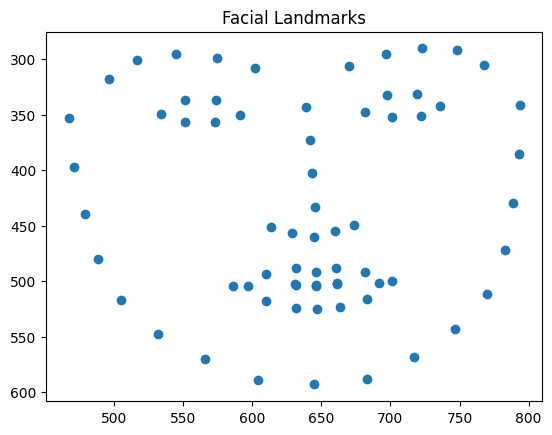

In [8]:
def frameImage(data, frame):      

    x = data[frame,:68]
    y = data[frame, 68:]
    
    plt.scatter(x,y)
    plt.gca().invert_yaxis()
    plt.title('Facial Landmarks')

data, emotions, actors = getData(actor=2, emotion=1, type='2d')

frameImage(data,5)

## 2.5

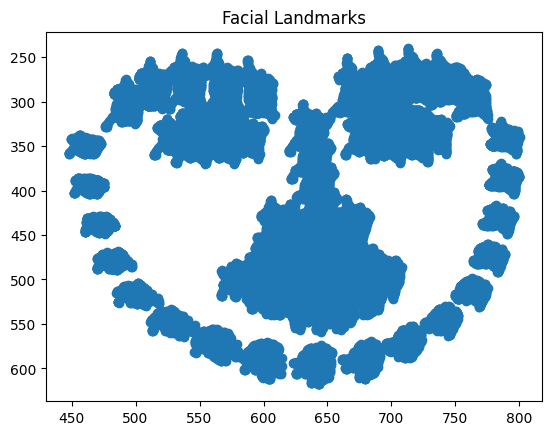

In [9]:
def frameImages(data, frames):      
    x = []
    y = []

    for f in frames:
        x.extend(data[f, :68])
        y.extend(data[f, 68:])
    
    plt.scatter(x,y)
    plt.gca().invert_yaxis()
    plt.title('Facial Landmarks')

data, emotions, actors = getData(actor=2, emotion=1, type='2d')

frames = [i for i in range(0,len(data))] # Range de frames a mostrar

frameImages(data, frames)

# 3

## 3.1

In [10]:
def normalizar(data, xmax= 1280, ymax=720):
    
    xref = data[:,27]
    yref = data[:,68+27]
    for j in range(136):
        if j <= 67:
            data[:,j] = (data[:,j] - xref)/xmax
        else:
            data[:,j] = (data[:,j] - yref)/ymax
    return data
    
data, emotions, actors = getData(type='2d')
landmarks_norm = normalizar(data)

In [11]:
print(landmarks_norm.shape)
print(landmarks_norm[:])

(299854, 136)
[[-0.12210937 -0.12320314 -0.12234376 ...  0.62291664  0.62416667
   0.62111115]
 [-0.12281251 -0.12390628 -0.1230469  ...  0.6223611   0.6234722
   0.6201389 ]
 [-0.1230469  -0.1242969  -0.12320314 ...  0.6226389   0.6236111
   0.62      ]
 ...
 [-0.12687501 -0.12476563 -0.11796878 ...  0.6873611   0.69138885
   0.6898611 ]
 [-0.12671873 -0.12460937 -0.11781249 ...  0.6890278   0.69291663
   0.69138885]
 [-0.12703125 -0.12492187 -0.11812501 ...  0.69138885  0.6954167
   0.6938889 ]]


## 3.2

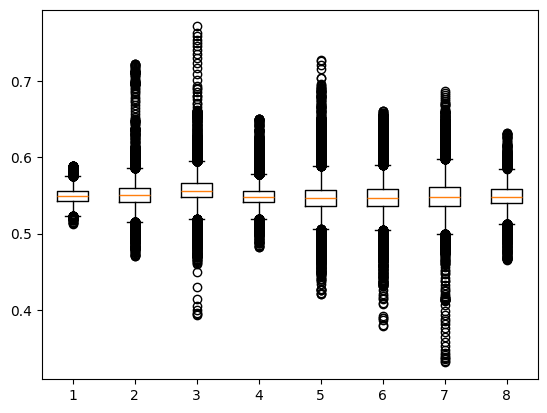

In [12]:
def boxplot(landmark='x_54'):
    landmark = landmark.split('_')
    posicao = int(landmark[1]) 

    todos = [None for i in range(8)]
    
    if landmark[0] != 'x':
        posicao += 68
    
    for i in range(len(todos)):
            data, emotions, actors = getData(emotion=i+1, type='2d')
            data = normalizar(data)
            todos[i] = data[:,posicao]
    
    plt.boxplot(todos)

boxplot()

## 3.3

In [13]:
def densidadeoutlier(data,landmark):
    landmark = landmark.split('_')
    posicao = int(landmark[1])
    
    if landmark[0] == 'y':
        posicao = posicao + 68
    
    Q1 = np.quantile(data[:,posicao],0.25)
    Q3 = np.quantile(data[:,posicao],0.75)

    intervalo = Q3 - Q1

    limiteinf = Q1 - 1.5*intervalo
    limitesup = Q3 + 1.5*intervalo

    outliers= np.where((data[:,posicao] < limiteinf) | (data[:,posicao] > limitesup))
    nonoutliers= np.where((data[:,posicao] >= limiteinf) & (data[:,posicao] <= limitesup))

    n0 = len(outliers[0])
    nr = len(outliers[0]) + len(nonoutliers[0])
    d = (n0 / nr) * 100
    return [float(d),outliers,nonoutliers]


In [14]:
landmarks_names = ["x_" + str(i) for i in range(68)]
landmarks_names.extend(["y_" + str(i) for i in range(68)])

def x():
    dens = {}
    for i in range(1,9):
        data, _ ,_ = getData(emotion=i,type='2d')
        data_norm = normalizar(data)

        dens[i] = []
        media = 0
        desvio = 0

        for j in landmarks_names:
            density = densidadeoutlier(data_norm,j)[0]
            dens[i].append(density)
    return dens

dens = x()

print("Médias --> Desvio padrão")
for i in range(1,9):
    print(np.mean(dens[i]), "-->",np.std(dens[i]))
    #print(np.std(dens[i]))

media_densidades = []

for i in range(len(dens[1])):
    med = []
    for j in range(1,len(dens)+1):
        med.append(dens[j][i])
    media_densidades.append(np.mean(med))

print("Lista das médias de densidades dos landmarks por ordem")
print(media_densidades)

Médias --> Desvio padrão
0.8314540082664111 --> 0.9262725364650273
1.7687880437236916 --> 1.5564808413964877
1.9475466127531207 --> 1.1983596506857797
2.1750006756806557 --> 1.7834599652498728
2.426917281207908 --> 1.8977504576800481
3.2985587679906057 --> 2.5178231867342085
3.0238621052029195 --> 2.3605717757214975
2.243978780620417 --> 1.9343304450631056
Lista das médias de densidades dos landmarks por ordem
[1.6604056721773752, 1.5810112266156655, 1.4697419939742353, 1.3288353507551698, 1.3783513172992596, 1.69945593938672, 2.209783611671123, 2.649579879259615, 3.595211955533654, 3.6931909346596967, 3.1654188795781093, 2.6235989603482066, 2.4184659780832174, 2.377022537299778, 2.355686803376654, 2.7043373674895, 3.406515451901975, 3.096750634900234, 3.1854050666317972, 2.312407906097854, 2.117366048414068, 2.285767417953738, 1.6306099083740344, 1.0707349182896768, 1.121781361467584, 1.2555161261768075, 1.704995577669297, 0.0, 4.659576522083549, 4.668304218038773, 4.594938582557042, 

Respetivamente as percentagens das densidades por emoção vão ser:

Médias --> Desvio padrão
0.709297878916461 --> 0.8332214991722479

1.8527635103497941 --> 1.5692586856455162

1.9343089117807517 --> 1.2368983419275188

2.131173571303965 --> 1.8848729527552068

2.2864276557302894 --> 1.9745728466903445

3.2564418402915525 --> 2.7234026569772873

2.850362086994522 --> 2.340299640372042

2.3433160423799797 --> 1.8975326380080588

As médias dos outliers por emoção vão variar entre 0.70% e 3.25% e os desvios padrões entre 0.83 e 2.72. Quanto às landmarks estas percentagens das densidades vão variar entre 0 e 4.9425.

Um desvio padrão maior por emoção poderá dizer que consoante a emoção as landmarks irão variar mais, por exemplo alguem calmo vai tendencialmente fazer menos movimentos do que alguém surpreendido ou irritado. 

## 3.4

In [15]:
def zScore(data, k=3, landmark=None):
    
    if landmark != None:
        landmark = landmark.split('_')
        posicao = int(landmark[1])
        if landmark[0] == 'x':
            data = data[:,posicao]
        else:
            data = data[:,posicao+68]
    
    mean = np.mean(data) 
    std = np.std(data) 
    z = (data - mean) / std
    idx_outliers = np.where(np.abs(z)>k)[0]
    idx_non_outliers = np.where(np.abs(z)<=k)[0]
    
    return idx_outliers, idx_non_outliers

# Print do número de outliers
print(len(zScore(landmarks_norm, 3.2, 'x_54')[0]))
print(len(zScore(landmarks_norm, 3.5, 'x_54')[0]))
print(len(zScore(landmarks_norm, 4, 'x_54')[0]))

3435
2514
1529


## 3.5 

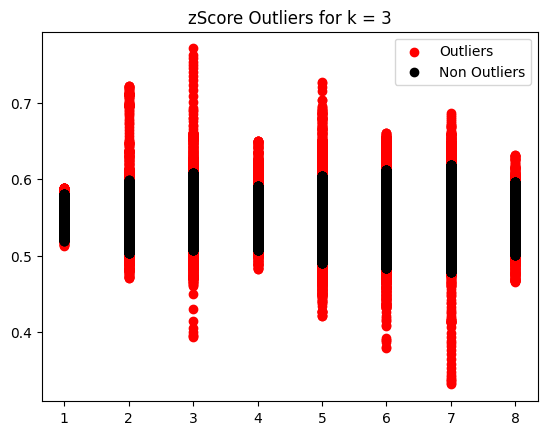

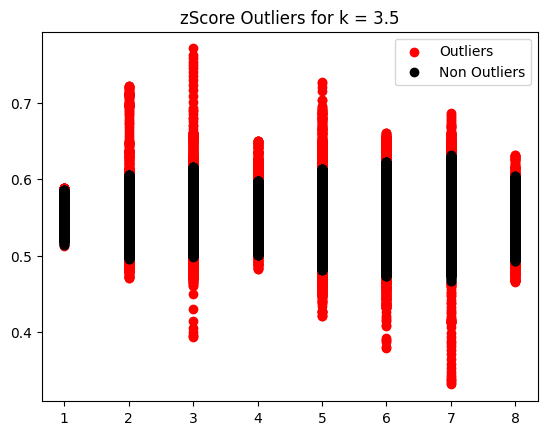

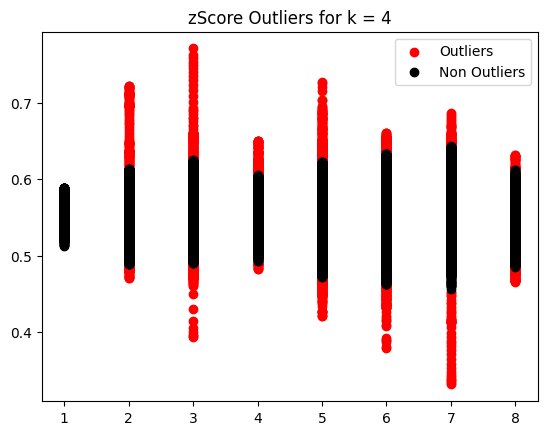

In [16]:
def zScore_plot(landmark='x_54', k1=3, k2=3.5, k3=4):
    
    landmark_s = landmark.split('_')
    posicao = int(landmark_s[1])
    
    if landmark_s[0] != 'x':
        posicao+=68
    
    #plot 1:
    
    for i in range(1,9):
        data, emotions, actors = getData(emotion=i, type='2d')
        data = normalizar(data)
        out, non_out = zScore(data, k1, landmark)
        x = np.ones(len(data[:,posicao][out]))
        plt.scatter(x*i ,data[:,posicao][out], c ='red')
        x = np.ones(len(data[:,posicao][non_out]))
        plt.scatter(x*i,data[:,posicao][non_out], c ='black')
    plt.title("zScore Outliers for k = " + str(k1))
    plt.legend(["Outliers", "Non Outliers"],loc='upper right')
    plt.show()
    
    #plot 2:
    
    for i in range(1,9):
        data, emotions, actors = getData(emotion=i, type='2d')
        data = normalizar(data)
        out, non_out = zScore(data, k2, landmark)
        x = np.ones(len(data[:,posicao][out]))
        plt.scatter(x*i ,data[:,posicao][out], c ='red')
        x = np.ones(len(data[:,posicao][non_out]))
        plt.scatter(x*i,data[:,posicao][non_out], c ='black')
    plt.title("zScore Outliers for k = " + str(k2))
    plt.legend(["Outliers", "Non Outliers"],loc='upper right')
    plt.show()
    
    #plot 3:
    
    for i in range(1,9):
        data, emotions, actors = getData(emotion=i, type='2d')
        data = normalizar(data)
        out, non_out = zScore(data, k3, landmark)
        x = np.ones(len(data[:,posicao][out]))
        plt.scatter(x*i ,data[:,posicao][out], c ='red')
        x = np.ones(len(data[:,posicao][non_out]))
        plt.scatter(x*i,data[:,posicao][non_out], c ='black')
    plt.title("zScore Outliers for k = " + str(k3))
    plt.legend(["Outliers", "Non Outliers"],loc='upper right')
    plt.show()
    
zScore_plot('x_54')

A fórmula do Z-Score é representada por (dados - distribuição média) / desvio padrão, que nos apresenta assim os dados normalizados, permitindo a comparação de dados com diferentes escalas.

Para detetar outliers, basta definir um threshold (o nosso k). É normal que quanto maior o k, maior a tolerância aos outliers.

O mesmo se consegue verificar nos exemplos em cima mostrados, quanto maior o k, menos outliers (pois mais tolerância aos mesmos).

## 3.6

Para o landmark especificado é possível de notar que a variabilidade é maior nos dados das emoções 2, 3, 5, 6 e 7. Esperando assim haver mais outliers nestasemoções, que é o que se pode verificar visualmente para ambas as visualizações (boxplot e Z-Score). 

Pelos resultados obtidos, conseguimos observar ainda que o k de valor 3 é a visualização que se parece  mais com o resultado do box plot, no entanto restringir esta variável para o valor 2 faria com que os resultados se aproximacem ainda mais.

## 3.7

In [17]:
class K_Means:
    def __init__(self, k=3, th=0.001, max_iter=300):
        self.k = k
        self.th = th
        self.max_iter = max_iter

    def distance(p1, p2):
        return np.sum((p1 - p2)**2)

    def initialize(self, data):
        
        centroids = []
        centroids.append(data[np.random.randint(data.shape[0]), :])

        for c_id in range(self.k - 1):

            dist = []
            for i in range(data.shape[0]):
                point = data[i, :]
                d = sys.maxsize

                for j in range(len(centroids)):
                    temp_dist = np.linalg.norm(point - centroids[j])
                    d = min(d, temp_dist)
                dist.append(d)

            dist = np.array(dist)
            next_centroid = data[np.argmax(dist), :]
            centroids.append(next_centroid)
            dist = []
            
        return centroids
    
    def fit(self,data):
        
        self.centroids = self.initialize(data)
        
        # Iterações K-means
        for i in range(self.max_iter):
            self.classifications = {}

            for i in range(self.k):
                self.classifications[i] = []
            
            # Escolher a que Cluster pertence o ponto
            for point in data:
                distances = [np.linalg.norm(point-self.centroids[centroid]) for centroid in range(len(self.centroids))]
                classification = distances.index(min(distances))
                self.classifications[classification].append(point)

            prev_centroids = self.centroids
            
            # Re-ajustar Centroides
            for classification in self.classifications:
                self.centroids[classification] = np.average(self.classifications[classification],axis=0)

            optimized = True
            
            # Ver se mudou mais que o th 
            for c in range(len(self.centroids)):
                original_centroid = prev_centroids[c]
                current_centroid = self.centroids[c]
                if np.sum((current_centroid-original_centroid)/original_centroid*100.0) > self.th:
                    optimized = False

            if optimized:
                break

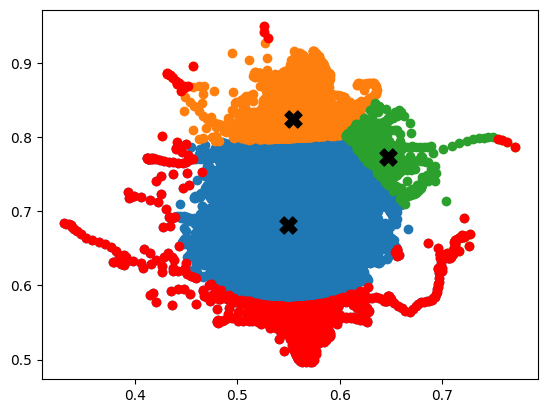

In [18]:
def kmeans (data, n, landmark='x_54', k=3, th=0.001):
    landmark = landmark.split('_')
    posicao = int(landmark[1])
    
    data = data[:, [posicao, posicao+68]]
    
    model = K_Means(k=n, th=th)
    model.fit(data)
    
    distancias = cdist(data, model.centroids)
    idx_centroides = np.argmin(distancias, axis=1)

    centers = np.empty((len(idx_centroides), 2))

    for i in range(len(model.centroids)):
        centers[np.where(idx_centroides == i)] = model.centroids[i]
    
    dist = np.linalg.norm(data - centers, axis = 1)
    idx_out, idx_nout = zScore(dist, k)
    
    return idx_out, idx_nout, model


def kmeans_plot (data, n_clust, landmark='x_54', k=3, th=0.001):
    
    landmark_s = landmark.split('_')
    posicao = int(landmark_s[1])
    
    out, nout, km = kmeans(data, n_clust, landmark, k, th)
    
    data = data[:, [posicao, posicao+68]]
    
    for i in km.classifications:
        points = np.array(km.classifications[i])
        plt.scatter(points[:,0], points[:,1])

    plt.scatter(data[out,0], data[out,1], c='red')

    cen = np.array(km.centroids)     
    plt.scatter(cen[:,0], cen[:,1], marker = "X", c = 'black', s=150)
    plt.show()

    
#out, idx_nout, km = kmeans(landmarks_norm, 3)
kmeans_plot(landmarks_norm, 3, 'x_54', 3)

## 3.8

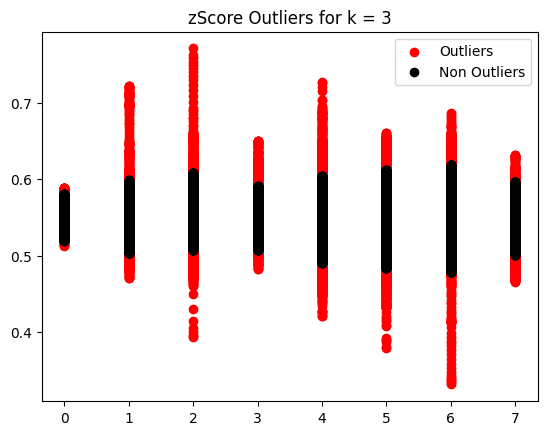

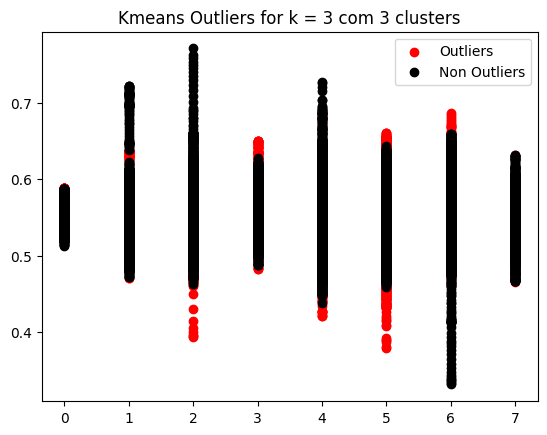

In [19]:
def zScore_kmeans(landmark='x_54',n=3, k=3):
    
    landmark_s = landmark.split('_')
    posicao = int(landmark_s[1])
    
    if landmark_s[0] != 'x':
        posicao+=68    
    
    # zScore
    for i in range(8):
        data, emotions, actors = getData(emotion=i+1, type='2d')
        data = normalizar(data)
        out, nout = zScore(data, k, landmark)
        x = np.ones(len(data[:,posicao][out]))
        plt.scatter(x*i ,data[:,posicao][out], c ='red')
        x = np.ones(len(data[:,posicao][nout]))
        plt.scatter(x*i,data[:,posicao][nout], c ='black')
    plt.title("zScore Outliers for k = " + str(k))
    plt.legend(["Outliers", "Non Outliers"],loc='upper right')
    plt.show()
        
    # Kmeans
    for i in range(8):
        data, emotions, actors = getData(emotion=i+1, type='2d')
        data = normalizar(data)
        out, nout, km = kmeans(data, n, landmark, k)
        x = np.ones(len(data[:,posicao][out]))
        plt.scatter(x*i ,data[:,posicao][out], c ='red')
        x = np.ones(len(data[:,posicao][nout]))
        plt.scatter(x*i,data[:,posicao][nout], c ='black')
    plt.title("Kmeans Outliers for k = " + str(k) + " com " + str(n) + " clusters")
    plt.legend(["Outliers", "Non Outliers"],loc='upper right')
    plt.show()
        
    
    plt.show()

zScore_kmeans('x_54',n=3,k=3)

Os gráficos de outliers segundo o algoritmo Z-Score e o K-means dão outliers bastante diferentes. 

Pelo plot do K-means parece também que não existem quase outliers, mas isso acontece devido a os outliers estarem mais espalhados verticalmente e o não oultiers são apenas "printados" depois, cobrindo assim alguns outliers.

Isto pode acontecer devido ao facto de que o Z-Score apenas lidar com dados a 1 dimensão, enquanto que o K-means lida com as duas componentes dos dados (coordenadas x e coordenadas y).

### 3.8.1

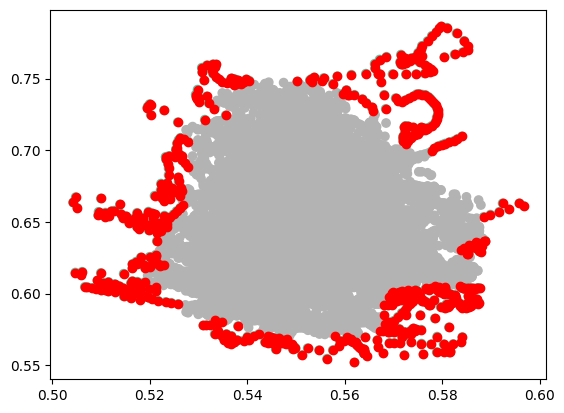

In [20]:
def dbscan (data, landmark, eps, min_samples):
    landmark = landmark.split('_')
    posicao = int(landmark[1])
    
    data = data[:, [posicao, posicao+68]]
    
    dbscan = DBSCAN(eps=eps, min_samples=min_samples)
 
    dbscan.fit(data)
 
    idx_out = np.where(dbscan.labels_ == -1)[0]
    idx_nout = np.where(dbscan.labels_ != -1)[0]
    
    return idx_out, idx_nout, dbscan

def dbscan_plot (data, landmark, eps, min_samples):
    
    landmark_s = landmark.split('_')
    posicao = int(landmark_s[1])
    
    out, nout, db = dbscan(data, landmark, eps, min_samples)
    
    data = data[:, [posicao, posicao+68]]
    
    plt.scatter(data[:,0], data[:,1], c=db.labels_, cmap='Set2')
    plt.scatter(data[out,0], data[out,1], c='red')
    plt.show()

#out, nout, db = dbscan(landmarks_norm[:25000], landmark = 'x_54', eps=0.006, min_samples=100)
dbscan_plot(landmarks_norm[:25000], landmark = 'x_54', eps=0.006, min_samples=100)   

O DBSCAN é eficaz em identificar outliers baseado na densidade, enquanto que o K-means agrupa dados em clusters (com mais sensibilidade a outliers). 

Para a detecção de outliers, o DBSCAN é a melhor opção quando a estrutura dos dados é complexa, como o nosssos dados.

Para esta implementação enviamos parte dos dados para o DBSCAN, pois dava-nos um erro de Memoria a testar.

## 3.9

In [21]:
def injecaoutliers(data,percentagem,landmark,k):
    
    valores_originais = []
    indexes_originais = []

    dens = densidadeoutlier(data,landmark)[0]
        
    if dens>percentagem:
        indexes = []
        return data,indexes,valores_originais
    
    while dens < percentagem:
        
        dens = densidadeoutlier(data,landmark)[0]
        #Vai tirar so os indexes
        outliers = densidadeoutlier(data,landmark)[1][0]
        nonoutliers = densidadeoutlier(data,landmark)[2][0]

        naooutliers = np.zeros(shape=len(nonoutliers), dtype=np.uint8)
        out = np.zeros(shape=len(outliers), dtype=np.uint8)

        landmarks = landmark.split('_')
        posicao = int(landmarks[1])

        if landmarks[0] == 'y':
            posicao = posicao + 68

        # Adicionar todos os valores dos outliers / não outliers a uma lista
        valores_non = []
        for i in range(len(nonoutliers)):
            valores_non.append(data[nonoutliers[i],posicao])

        valores_out = []
        for i in range(len(outliers)):
            valores_out.append(data[outliers[i],posicao])

        dif = percentagem/100 - dens/100

        #Numero de novos outliers
        
        nrnovosout = round(dif * len(data[:,posicao]))

        #Escolha aleatoria de indices para passarmos de não outliers para outliers
        
        indexes = np.random.choice(nonoutliers, size=nrnovosout, replace=False)
        
        #TRANSFORMAÇÃO
        
        mi = np.mean(data[:,posicao])
        sigma = np.std(data[:,posicao])
        for i in range(len(indexes)):
            valores_originais.append(data[indexes[i],posicao])
            indexes_originais.append(indexes[i])
            np.delete(nonoutliers,np.where(nonoutliers == indexes[i]))
            np.append(outliers,indexes[i])
            s =  random.choice([-1, 1])
            z = mi*s + (k*sigma)
            q = A=np.random.uniform(low=0,high=z)
            ponto = mi + (s * k * sigma) + s*q
            data[indexes[i],posicao] = ponto
        
    return data,indexes_originais,valores_originais,nonoutliers,outliers

In [22]:
data, emotions, actors = getData(type='2d')
landmarks_norm = normalizar(data)

data,indexes,valores_originais,nonoutliers,outliers = injecaoutliers(landmarks_norm,5,'x_54',4)

data, emotions, actors = getData(type='2d')
landmarks_norm = normalizar(data)

data,indexes,valores_originais,nonoutliers,outliers = injecaoutliers(landmarks_norm,5,'x_54',3.5)

data, emotions, actors = getData(type='2d')
landmarks_norm = normalizar(data)
                                           
data,indexes,valores_originais,nonoutliers,outliers = injecaoutliers(landmarks_norm,5,'x_54',3)

## 3.10

In [304]:
def modelolinear(amostra,p,indexes,mode=None): 
    length = int(len(amostra))
    lengthind = int(len(indexes))

    # Vamos pegar na densidade dos outliers. Ver a diferença entre essa e a percentagem que queremos
    # Esse valor de % vamos fazer % * len(dados) para ver quantos precisamos substituir, vamos pegar
    # em x nonoutliers, guardar os seus valores e trocar para valores novos de outliers
    
    if mode is None:
        X = []
        Y = []
        contador = 0
        #Contador vai fazer com que salte as proximas p posições quando encontra um outlier, para os outliers não aparecerem na matriz
        for i in range(p,len(amostra)):
            if contador == 0:
                if i in indexes:
                    #contador = contador + (p+1)
                    contador = p
                else:
                    x_aux = [1]
                    x_aux.extend(amostra[i-p:i])
                    Y.append(amostra[i])
                    X.append(x_aux)
            else:
                contador = contador - 1
                if i in indexes:
                    contador = p
        X = np.array(X)
        Y = np.array(Y)
        print(X)
        print(Y)
        Beta = np.dot(np.linalg.pinv(X),Y.T) 
             
    else:
        X = []
        Y = []
        contador = 0
        for i in range(int(p/2),len(amostra)-int(p/2)):
            if contador == 0:
                if i+int(p/2) in indexes:
                    contador = p
                else:
                    x_aux = [1]
                    x_aux.extend(amostra[i-int(p/2):i])
                    x_aux.extend(amostra[i+1:i+1+int(p/2)])
                    X.append(x_aux)
                    Y.append(amostra[i+int(p/2)])
            else:
                contador = contador - 1
                if i+int(p/2) in indexes:
                    contador = p
        X = np.array(X)
        Y = np.array(Y)
        Beta = np.dot(np.linalg.pinv(X),Y.T) 
        
    return Beta

In [24]:
data, emotions, actors = getData(type='2d')
landmarks_norm = normalizar(data)

teste = landmarks_norm[:,54]

data_novo,indexes,valores_originais,nonoutliers,outliers = injecaoutliers(landmarks_norm,5,'x_54',4)

Beta = modelolinear(teste,3,indexes)

print(Beta)

[[1.         0.54679692 0.54734373 0.54742187]
 [1.         0.54734373 0.54742187 0.54742187]
 [1.         0.54742187 0.54742187 0.54718751]
 ...
 [1.         0.53828126 0.54124999 0.54343748]
 [1.         0.54124999 0.54343748 0.54468751]
 [1.         0.54343748 0.54468751 0.54617184]]
[0.5474219  0.5471875  0.5469531  ... 0.5446875  0.54617184 0.54710937]
[ 0.01187508 -0.10136327 -0.14198779  1.22176736]


In [25]:
data, emotions, actors = getData(type='2d')
landmarks_norm = normalizar(data)

teste = landmarks_norm[:,125]
print(teste)

data_novo,indexes,valores_originais,nonoutliers,outliers = injecaoutliers(landmarks_norm,5,'y_57',4)

Beta = modelolinear(teste,4,indexes,mode="centrado")

print(Beta)

[0.6536111  0.65263885 0.65236115 ... 0.72680557 0.7277778  0.7301389 ]
[[1.         1.22835076 0.65263885 0.65222222 0.65222222]
 [1.         0.65263885 0.65236115 0.65222222 0.65319443]
 [1.         0.65513891 0.65625    0.65694445 0.65763891]
 ...
 [1.         0.74430561 0.7386111  0.72625005 0.72500002]
 [1.         0.7386111  0.73041672 0.72500002 0.72680557]
 [1.         0.73041672 0.72625005 0.72680557 0.72777778]]
[0.6522222  0.6531944  0.6576389  ... 0.725      0.72680557 0.7277778 ]
226004
226004
(226004, 5)
(226004,)
[ 0.00000000e+00  1.88737914e-15 -3.49199836e-15  9.78384040e-16
  1.00000000e+00]


## 3.11

In [26]:
def predicaopontos(data,landmark,p,percentagem,k):
    landmarks = landmark.split('_')
    posicao = int(landmarks[1])

    if landmarks[0] == 'y':
        posicao = posicao + 68
        
    data_novo,indexes,valores_originais,nonoutliers,outliers = injecaoutliers(landmarks_norm,percentagem,landmark,k)
    dados = data[:,posicao]
    Beta = modelolinear(dados,p,indexes)

    previsto = []
    
    for i in indexes:
        ponto = float(Beta[0])
        ponto += np.dot(data_novo[i-p:i,posicao],Beta[1:].T)
        data_novo[i,posicao] = ponto
        previsto.append(ponto)
    
    dist = np.zeros(shape = (len(indexes)))
    for i in range(len(indexes)):
        dist[i] = np.sqrt((data_novo[indexes[i],posicao] - valores_originais[i])**2)

    fig, axs = plt.subplots(2)
    fig.suptitle('Grafico de distancias dos pontos e Histograma das distâncias')
    axs[0].scatter(range(len(valores_originais[:20])),valores_originais[:20],c='blue')
    axs[0].scatter(range(len(valores_originais[:20])),previsto[:20],c='red')
    axs[0].legend(["Valores originais", "Valores previstos"], loc='upper left', bbox_to_anchor=(1, 0.5))
    axs[1].hist(dist,int(len(dist)/10))
    axs[1].set_xlim(0, 0.2)
    axs[1].set_ylim(0, 5000) 


    plt.show()
    
    return np.mean(dist)

[[1.         0.65361112 0.65263885 0.65236115]
 [1.         0.65319443 0.65402776 0.65513891]
 [1.         0.65402776 0.65513891 0.65625   ]
 ...
 [1.         0.73041672 0.72625005 0.72500002]
 [1.         0.72625005 0.72500002 0.72680557]
 [1.         0.72500002 0.72680557 0.72777778]]
[0.6522222  0.65625    0.65666664 ... 0.72680557 0.7277778  0.7301389 ]


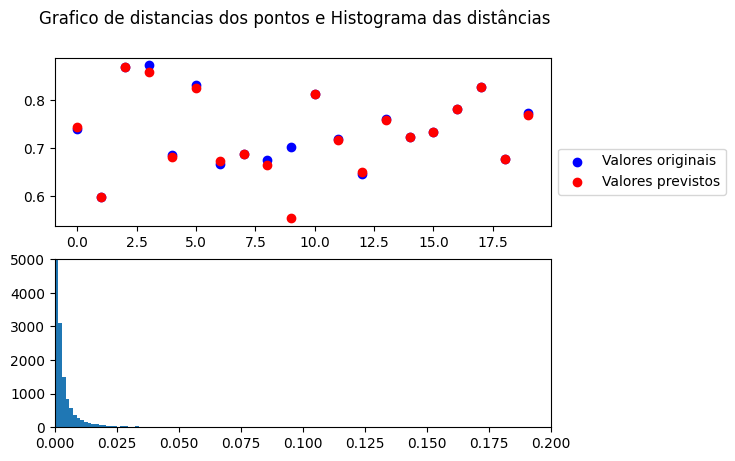

In [27]:
data, emotions, actors = getData(type='2d')
landmarks_norm = normalizar(data)
value = predicaopontos(landmarks_norm,'y_57',3,5,4)

[[1.         0.65361112 0.65263885]
 [1.         0.65263885 0.65236115]
 [1.         0.65236115 0.65222222]
 ...
 [1.         0.72625005 0.72500002]
 [1.         0.72500002 0.72680557]
 [1.         0.72680557 0.72777778]]
[0.65236115 0.6522222  0.6522222  ... 0.72680557 0.7277778  0.7301389 ]


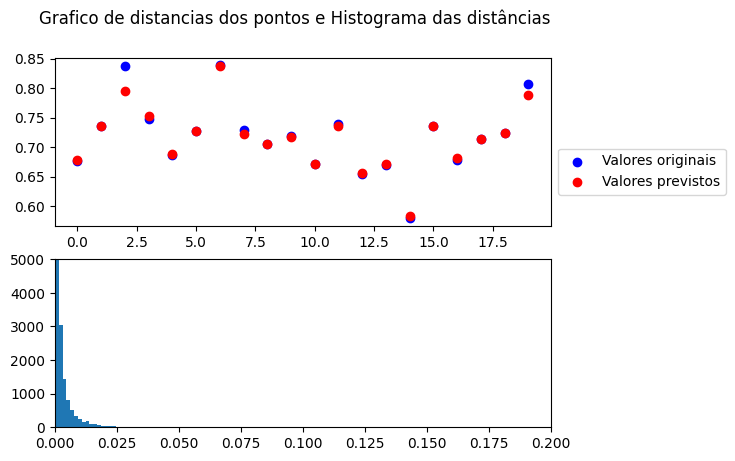

Com p igual a 2 é: 0.030931859489902104
[[1.         0.65361112 0.65263885 0.65236115]
 [1.         0.65263885 0.65236115 0.65222222]
 [1.         0.65236115 0.65222222 0.65222222]
 ...
 [1.         0.73041672 0.72625005 0.72500002]
 [1.         0.72625005 0.72500002 0.72680557]
 [1.         0.72500002 0.72680557 0.72777778]]
[0.6522222  0.6522222  0.6531944  ... 0.72680557 0.7277778  0.7301389 ]


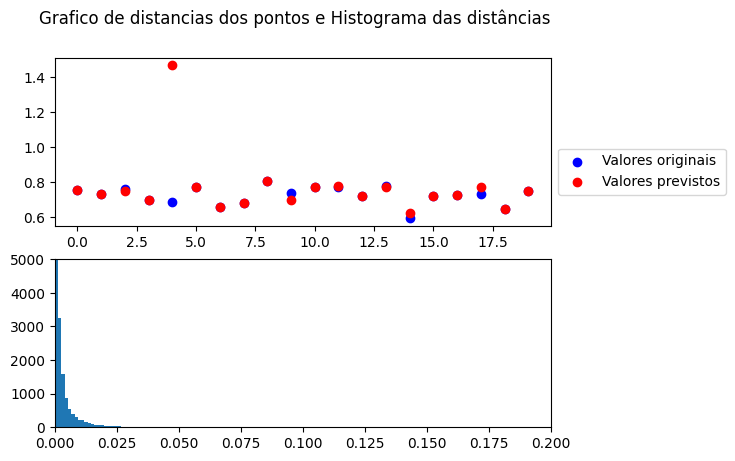

Com p igual a 3 é: 0.028891753585233618
[[1.         0.65625    0.65666664 0.65694445 0.65763891]
 [1.         0.65666664 0.65694445 0.65763891 0.65791667]
 [1.         0.65694445 0.65763891 0.65791667 0.65833336]
 ...
 [1.         0.7386111  0.73041672 0.72625005 0.72500002]
 [1.         0.73041672 0.72625005 0.72500002 0.72680557]
 [1.         0.72625005 0.72500002 0.72680557 0.72777778]]
[0.65791667 0.65833336 0.65902776 ... 0.72680557 0.7277778  0.7301389 ]


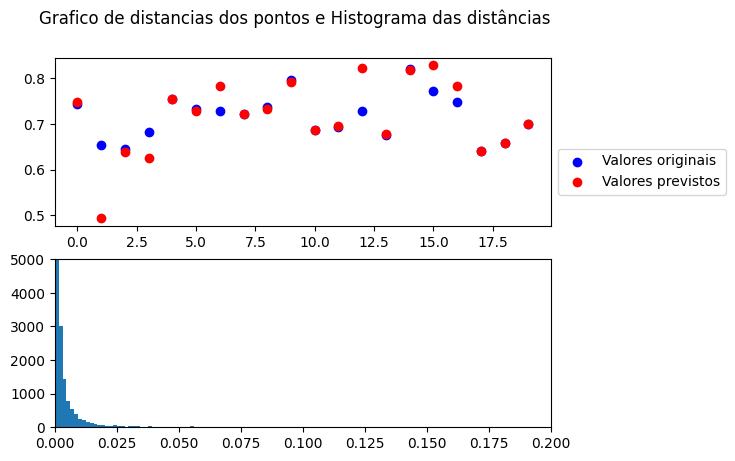

Com p igual a 4 é: 0.0314866961933106
[[1.         0.65361112 0.65263885 0.65236115 0.65222222 0.65222222]
 [1.         0.65263885 0.65236115 0.65222222 0.65222222 0.65319443]
 [1.         0.65625    0.65666664 0.65694445 0.65763891 0.65791667]
 ...
 [1.         0.74458331 0.74555552 0.74638891 0.74694443 0.74638891]
 [1.         0.74555552 0.74638891 0.74694443 0.74638891 0.74430561]
 [1.         0.74638891 0.74694443 0.74638891 0.74430561 0.7386111 ]]
[0.6531944  0.65402776 0.65833336 ... 0.7443056  0.7386111  0.7304167 ]


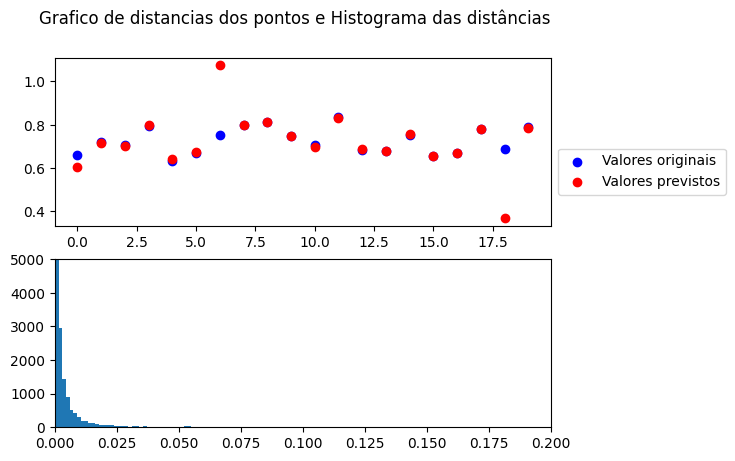

Com p igual a 5 é: 0.03266026288345515


In [30]:
teste = [i for i in range(2,6)]

for i in range (len(teste)):
    data, emotions, actors = getData(type='2d')
    landmarks_norm = normalizar(data)
    value = predicaopontos(landmarks_norm,'y_57',teste[i],5,4)
    print("Com p igual a " + str(teste[i]) + " é: " + str(value))

O erro de predição foi calculado fazendo a raiz do quadrado da distância do valor original ao valor previsto. Para o nosso modelo fomos testar 4 valores de p diferentes sendo este p o que determina o numero de valores anteriores que vai buscar. Foram testados os valores de 2,3,4,5 pontos os resultados foram:

2 --> 0.0309

3 --> 0.0288

4 --> 0.0314

5 --> 0.0326

O reultado menos fiável seria o do p = 2 pois reparamos com as várias repetições que era o valor que mais variava entre 0.0185 e 0.0220, enquanto que nos outros valores de p não variavam muito da média das 30 tentativas. É importante ressaltar que estas 30 tentativas foram feitas sempre nas mesmas condições comparando sempre o mesmo landmark, neste caso o y_57', o mesmo valor de percentagem, 5% e com um k a 4. 
    
Consideramos como o melhor p o valor de 5 para o nosso modelo porém este valor exige um maior poder computacional que um p mais baixo que não demonstrava valores tão distantes dos obtidos no p=5. Analisando agora os gráficos temos um gráfico em cima que mostra a distância dos primeiros 20 pontos originais, a azul, aos seus respetivos valores previstos, a vermelho. No gráfico de baixo temos um histograma das distâncias, podemos observar que as distâncias aproximam-se muito de 1 sendo que vão diminuindo à medida que se vai afastando do 1, sendo por isso muito pontiagudo no início.

## 3.12

In [305]:
def predicaopontos2(data,landmark,p,percentagem,k):
    landmarks = landmark.split('_')
    posicao = int(landmarks[1])

    if landmarks[0] == 'y':
        posicao = posicao + 68
    
    data_novo,indexes,valores_originais,nonoutliers,outliers = injecaoutliers(landmarks_norm,percentagem,landmark,k)
    Betas= [modelolinear(data[:,posicao-1+i],p,indexes,mode="centrado") for i in range(3)]
    previsto = []
    
    for i in indexes:
        pontos = []
        for l in range (len(Betas)):
            ponto = float(Betas[l][0])
            for j in range (p):
                val = float(data_novo[i-(j+1),posicao]) * float(Betas[l][j+1])
                ponto += val
            pontos.append(ponto)
        data_novo[i,posicao] = np.mean(pontos)
        previsto.append(np.mean(pontos))
    
    dist = np.zeros(shape = (len(indexes)))
    for i in range(len(indexes)):
        dist[i] = np.sqrt((data_novo[indexes[i],posicao] - valores_originais[i])**2)
    
    fig, axs = plt.subplots(2)
    fig.suptitle('Grafico de distancias dos pontos e Histograma das distâncias')
    axs[0].scatter(range(len(valores_originais[:20])),valores_originais[:20],c='blue')
    axs[0].scatter(range(len(valores_originais[:20])),previsto[:20],c='red')
    axs[0].legend(["Valores originais", "Valores previstos"], loc='upper left', bbox_to_anchor=(1, 0.5))
    axs[1].hist(dist,int(len(dist)/10))
    axs[1].set_xlim(0, 0.2)
    axs[1].set_ylim(0, 5000) 


    plt.show()

    
    return np.mean(dist)

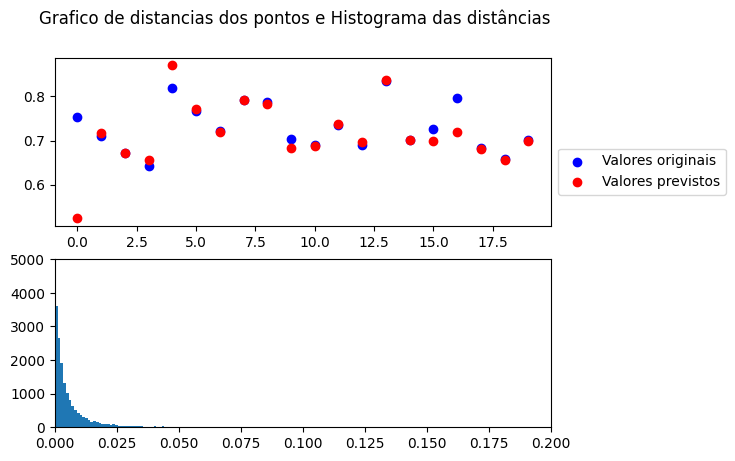

0.02443555201756235


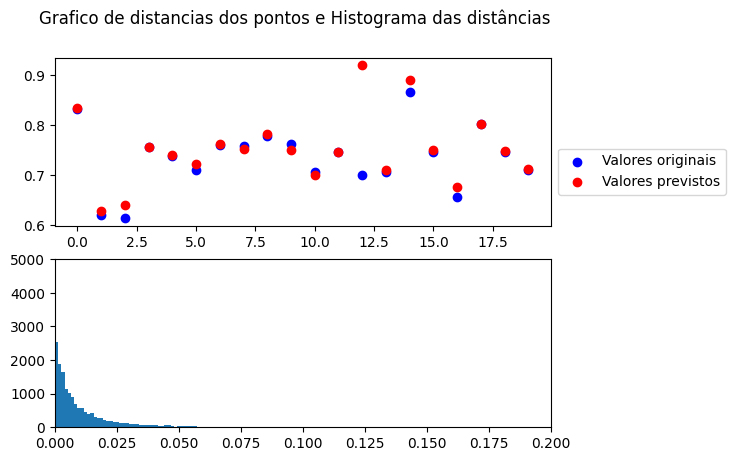

0.02633394807076837


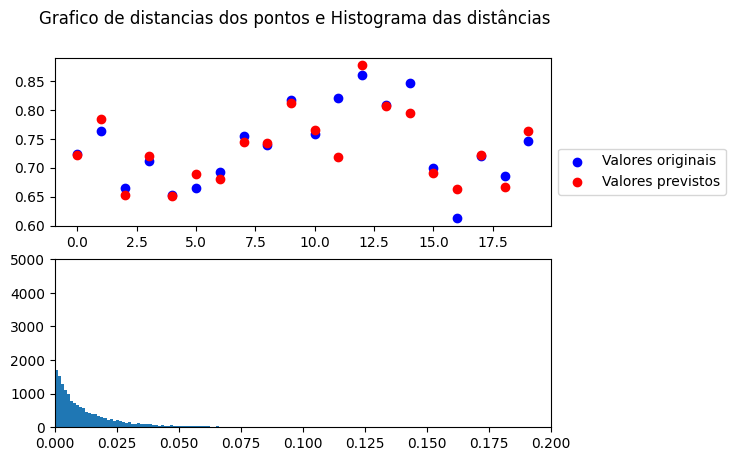

0.03176937988016047


In [306]:
#Nota: O código do predicaopontos2 poderá demorar algum tempo a correr +-30minutos

data, emotions, actors = getData(type='2d')
landmarks_norm = normalizar(data)

mean = predicaopontos2(landmarks_norm,'y_57',2,5,4)

print(mean)

data, emotions, actors = getData(type='2d')
landmarks_norm = normalizar(data)

mean = predicaopontos2(landmarks_norm,'y_57',4,5,4)

print(mean)

data, emotions, actors = getData(type='2d')
landmarks_norm = normalizar(data)

mean = predicaopontos2(landmarks_norm,'y_57',6,5,4)

print(mean)

O erro de predição foi calculado fazendo a raiz do quadrado da distância do valor original ao valor previsto. Para o nosso modelo fomos testar 3 valores de p pares diferentes sendo que p/2 o que determina o numero de valores anteriores e posteriores que vamos buscar. Foram testados os valores de 2,4,6 que vão ser respetivamente 1,2,3 valores antes e depois. Os resultados foram:

2 --> 0.0244

4 --> 0.0263

6 --> 0.0317

Comparando agora os resultados da abordagem 3.12 com a 3.11 podemos notar que obtivemos um melhor resultado média na abordagem 3.12 pois o calculo do ponto torna-se mais preciso quando lhe são fornecidos valores dos vizinhos anteriores e posteriores e não só os valores anteriores. Contudo o tempo de processamenteo desta abordagem demora muito mais a ser feita, muito provavelmente por causa da implementação não ser a mais correta e à medida que se aumenta o p o tempo de processamento aumenta. Analisando os gráficos conseguimos observar que os valores da distância entre o ponto previsto, a vermelho e o valor original, a azul são muito semelhante, tendo o modelo conseguido diminuir em cerca de 0.01 deste modelo para a abordagem anterior. O histograma continua muito semelhante, tento a maior quantidade de valores perto do valor de distância 0 sendo esse muito pontiagudo nessa região.

# 4

## 4.1 (todas as alíneas)

In [35]:
def area(corners): 
    #Shoelace method
    n = len(corners)
    area = 0.0
    for i in range(n):
        j = (i + 1) % n
        area += corners[i][0] * corners[j][1]
        area -= corners[j][0] * corners[i][1]
    area = 0.5 * abs(area)
    return area


def calculate_area(data, landmarks):
    area = []
    for i in range(len(data)):
        corners =[]
        for n in landmarks:
            corners.append(data[i,[n,n+68]])
        area.append(corners)
    return np.std(area)

def area_eyes(data, landmarks):
    std = calculate_area(data,landmarks[:6]) + calculate_area(data,landmarks[6:])
    return std/2


# Angles
def angle(data, landmarks):
    angle = []
    for i in range(len(data)):
        points =[]
        for n in landmarks:
            points.append(data[i,[n,n+68]])
        ba = points[0] - points[1]
        bc = points[2] - points[1]
        cosine_angle = np.dot(ba, bc) / (np.linalg.norm(ba) * np.linalg.norm(bc))
        angle.append(np.arccos(cosine_angle))
    return np.std(points)


# Distances
def dist(data, landmarks):
    dist = []
    for i in range(len(data)):
        points =[]
        for n in landmarks:
            points.append(data[i,[n,n+68]])
        d = np.sqrt( (points[1][0] - points[0][0])**2 + (points[1][1] - points[0][1])**2 )
        dist.append(d)
    return np.std(dist)

def brow_dist(data,landmarks):
    std = dist(data,landmarks[:2]) + dist(data,landmarks[2:])
    return std/2

In [36]:
def add_features(frames):
    land_x = [x+17 for x in range(10)]
    land_y = [x+68 for x in land_x]
    land = land_x +land_y
    features = []
    emotion = []
    
    eyes = [36,37,38,39,40,41,42,43,44,45,46,47]
    mouth = [60,61,62,63,64,65,66,67]
    mouth_ang = [57,48,51]
    eye_brow1 = [21,39,22,42]
    eye_brow2 = [19,37,24,44]

    for e in range(8):
        data3d, emotions, actors = getData(emotion=e+1, type='3d')
        for i in range(data3d.shape[0]):
            f_data =[]

            # Single video normalized
            video = data3d[i, :, :frames[i]].T
            data = normalizar(video)

            # Landmarks
            for l in land:
                f_data.append(float(np.mean(data[:,l])))                

            # Areas
            f_data.append(area_eyes(data, eyes))
            f_data.append(calculate_area(data, mouth))

            # Angles
            f_data.append(angle(data, mouth_ang))

            # Distances
            f_data.append(brow_dist(data, eye_brow1))
            f_data.append(brow_dist(data, eye_brow2))
            
            # Save
            if len(np.where(np.isnan(f_data))[0])==0:
                features.append(f_data)
                
                # Emotion
                emotion.append(e+1)
                
                
    return np.array(features), np.array(emotion)

frames = np.load('frames.npy')
extracted, emotions = add_features(frames)

## 4.2

In [37]:
def shapiro_test(dados):
    
    res = []
    
    for feature in range(len(dados[0])):
        sh = shapiro(dados[:,feature]).pvalue
        res.append(sh)
        
    return res

sh_result = shapiro_test(extracted)

In [38]:
def parametric(ext, emotions, sh_result, threshold=0.05):
    
    emo = []
    res = np.zeros(len(sh_result))
    
    # Separate Emotions
    for i in range(len(np.unique(emotions))):
        emotion = []
        emotion.append(np.where(emotions==(i+1))[0])
        emo.append(emotion[0][0])  
    
    # Tests
    for f in range(len(sh_result)):
        if sh_result[f] >= threshold: # One Way ANOVA
            p = f_oneway(ext[emo[0]:emo[1]-1,f], ext[emo[1]:emo[2]-1,f], ext[emo[2]:emo[3]-1,f], 
                         ext[emo[3]:emo[4]-1,f], ext[emo[4]:emo[5]-1,f], ext[emo[5]:emo[6]-1,f],
                         ext[emo[6]:emo[7]-1,f], ext[emo[7]:,f]).pvalue
            
        else:                         # Kruskal Wallis
            p = kruskal(ext[emo[0]:emo[1]-1,f], ext[emo[1]:emo[2]-1,f], ext[emo[2]:emo[3]-1,f], 
                        ext[emo[3]:emo[4]-1,f], ext[emo[4]:emo[5]-1,f], ext[emo[5]:emo[6]-1,f],
                        ext[emo[6]:emo[7]-1,f], ext[emo[7]:,f]).pvalue
        
        if p <= threshold:
            np.put(res,f,1)
    
    return res
                
results = parametric(extracted, emotions, sh_result)

for i in range(len(results)):
    if results[i] == 1:
        print("Feature",i+1, ": Significant")
    else:
        print("Feature",i+1, ": Non Significant")

Feature 1 : Significant
Feature 2 : Significant
Feature 3 : Significant
Feature 4 : Significant
Feature 5 : Significant
Feature 6 : Significant
Feature 7 : Significant
Feature 8 : Significant
Feature 9 : Significant
Feature 10 : Significant
Feature 11 : Significant
Feature 12 : Significant
Feature 13 : Significant
Feature 14 : Significant
Feature 15 : Significant
Feature 16 : Significant
Feature 17 : Significant
Feature 18 : Significant
Feature 19 : Significant
Feature 20 : Significant
Feature 21 : Significant
Feature 22 : Significant
Feature 23 : Significant
Feature 24 : Significant
Feature 25 : Significant


## 4.3

In [120]:
def pca_fit(extraxted):
    # normalizar através do z-score
    media = np.mean(extracted)
    desvio_padrao = np.std(extracted)
    
    ext_norm = (extracted - media) / desvio_padrao


    pca = PCA()

    x = pca.fit_transform(ext_norm)

    return pca.fit(ext_norm),x

## 4.4

In [121]:
def pca_analyses(extracted, perc=0.75):
    
    pca = PCA().fit(extracted)
    
    variability = pca.explained_variance_ratio_
    
    cumulative_variability = np.cumsum(variability)
    num_vars = np.argmax(cumulative_variability >= perc)
    
    return variability, num_vars

percentagem = 0.75
var, n_pc = pca_analyses(extracted, percentagem)

print("Para explicar", percentagem*100,"% do feature set, devemos usar", n_pc,"variáveis.")

Para explicar 75.0 % do feature set, devemos usar 2 variáveis.


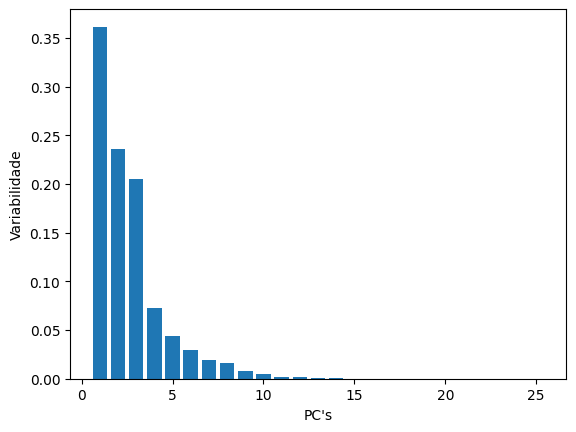

In [122]:
plt.bar(range(1,len(var)+1), var)
plt.xlabel("PC's")
plt.ylabel("Variabilidade")
plt.show()

### 4.4.1

In [124]:
def pc_video(video, pc_num=3):
    
    pca = pca_fit(video)[0]
    pc = pca.components_[:pc_num]
    print(pca.components_.shape)
    
    return np.dot(pc,video)

video_0 = extracted[0]
pc_video(video_0, 2)

(25, 25)


array([ 0.16617121, -0.07123126])

### 4.4.2

    O PCA destaca-se pela capacidade de reduzir a dimensionalidade dos dados nas suas componentes principais, o que simplifica a complexidade sem perder informação. Além disso, possibilita uma fácil visualização dos dados, especialmente quando reduzido a 2 ou 3 componentes principais. Remove ainda correlações entre variáveis nos dados.
    No entanto, perde a interpretabilidade dos dados. Assume ainda que as relações entre variáveis são lineares, o que pode ser uma limitação no caso de não serem. É também sensível à escala dos dados e a presença de outliers (análise pode vir a ser influenciada por esses elementos, distorcendo os dados).

## 4.5

In [43]:
def FisherScore(extracted,emotions,n_neighbors=10,mode='normal'):
    media_geral = []
    emo = []
    
    if mode == 'normal':
        r = 25
    else:
        r = 30
    
    for j in range(r):
        media_geral.append(np.mean(extracted[:,j]))
        
    
    for i in range(len(np.unique(emotions))):
        emotion = []
        emotion.append(np.where(emotions==(i+1))[0])
        emo.append(emotion[0][0]) 

    emo.append(len(emotions)+1)
    FisherScore = np.array([])

    for f in range(len(extracted[1])):
        SSB = 0
        SSW = 0
        DFB = len(np.unique(emotions))-1
        DFW = extracted.shape[0] - len(np.unique(emotions))
        for i in range(len(np.unique(emotions))):
            grupo = extracted[emo[i]:emo[i+1]-1,f]
            SSB += len(grupo) * (np.mean(grupo) - media_geral[f])**2
            SSW += (sum(grupo) - np.mean(grupo))**2
        MSB =  SSB / DFB
        MSW = SSW / DFW
        F= MSW / MSB
        FisherScore = np.append(FisherScore,F)
    
    return np.argsort(-FisherScore)[:n_neighbors]

In [44]:
def reliefF(extracted, emotions, n_neighbors=10):
    weights = np.zeros(len(extracted[1]))

    for i in range(len(extracted)):
        distances = np.sum((extracted - extracted[i])**2, axis=1)
        neighbors = np.argsort(distances)[1:n_neighbors+1]

        same_class = np.where(emotions[neighbors] == emotions[i])[0]
        diff_class = np.where(emotions[neighbors] != emotions[i])[0]
        weights += np.sum(extracted[neighbors[same_class]] - extracted[i], axis=0)
        weights -= np.sum(extracted[neighbors[diff_class]] - extracted[i], axis=0)
        
    return np.argsort(-weights)[:n_neighbors]

## 4.6

## 4.6.1

In [45]:
fisherscore = FisherScore(extracted,emotions)

print("10 melhores features de acordo com o FisherScore: " + str(fisherscore))

relieff = reliefF(extracted,emotions)

print("10 melhores features de acordo com o ReliefF: " + str(relieff))

instante = 0
fs = extracted[instante, fisherscore] 
print("Features do instante", instante, "para o Fisher Score:", fs)

rf = extracted[instante, relieff]
print("Features do instante", instante, "para o ReliefF:", rf)

10 melhores features de acordo com o FisherScore: [ 9  0  8  1  7  2  6  3 11 18]


10 melhores features de acordo com o ReliefF: [24 23 10 19 20 11 21 22 18  0]
Features do instante 0 para o Fisher Score: [ 0.10518815 -0.09895887  0.08915259 -0.08552058  0.06853476 -0.06534678
  0.04806441 -0.04422114 -0.04308673 -0.05161706]
Features do instante 0 para o ReliefF: [ 0.00619499  0.00520185 -0.01844105 -0.03236394  0.04414975 -0.04308673
  0.07517635  0.09315351 -0.05161706 -0.09895887]


### 4.6.2

    O Fisher score vai ser um método de feature selection que nos vai permitir escolher as melhores features consoante a média das classes está separada em relação à variabilidade das classes, tendo assim como objetivo selecionarmos as features mais discriminativas para construirmos um modelo melhor.
    O ReliefF vai ser um outro método de feature selection que vai calcular a distância aos pontos da mesma classe enquanto tenta maximizar a distância aos pontos de outras classes mais próximas. O seu valor do peso vai ser maior quanto mais perto estiver de vários da mesma classe.
    Consideramos como a principal vantagem desta abordagem de se utilizarem apenas as 10 melhores features o facto de reduzir a complexidade do modelo, não sendo necessário utilizarmos as 25 features que tinhamos inicialmente. Como contrapartida o facto de não utilizarmos 15 das 25 features vamos estar a desperdiçar informação que poderia ser útil no problema. Um outro problema pode estar associado com a escolha das features inicialmente que se nenhuma das 25 features for significativa para demonstrar a diferença entre as emoções o facto de utilizarmos somente 10 vai ser um tanto quanto redundante visto em pouca informação estarmos a adicionarmos ao modelo. Por outro lado o facto de ter somente 10 features pode ajudar no parâmetro da interpretabilidade pois conseguimos perceber muito mais facilmente quais são as features que em mais explicam as necessidades do nosso modelo. Com o facto de estarmos a reduzir a somente 10 features, outras possíveis features que seriam muito semelhantes sendo estas redundates acabam por não ser utlizadas no modelo. Temos também importante ressaltar que um problema com menos features acaba por consumir menos do poder de processamento da máquina pelo que em certos problemas uma redução do numero de features as 10 mais significativas poderá ser uma boa abordagem a se tomar.

# Parte B

# 1

## 1.1.1

In [128]:
from sklearn.model_selection import train_test_split

def tt_split(X,y, p=0.7):
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=p)
    
    return X_train, X_test, y_train, y_test

## 1.1.2

In [129]:
def actorsnonan(frames):
    atores = []
    land_x = [x+17 for x in range(10)]
    land_y = [x+68 for x in land_x]
    land = land_x +land_y
    features = []
    emotion = []
    
    eyes = [36,37,38,39,40,41,42,43,44,45,46,47]
    mouth = [60,61,62,63,64,65,66,67]
    mouth_ang = [57,48,51]
    eye_brow1 = [21,39,22,42]
    eye_brow2 = [19,37,24,44]

    for e in range(24):
        data3d, emotions, actors = getData(actor=e+1, type='3d')
        for i in range(data3d.shape[0]):
            f_data =[]

            # Single video normalized
            video = data3d[i, :, :frames[i]].T
            data = normalizar(video)

            # Landmarks
            for l in land:
                f_data.append(float(np.mean(data[:,l])))                

            # Areas
            f_data.append(area_eyes(data, eyes))
            f_data.append(calculate_area(data, mouth))

            # Angles
            f_data.append(angle(data, mouth_ang))

            # Distances
            f_data.append(brow_dist(data, eye_brow1))
            f_data.append(brow_dist(data, eye_brow2))
            
            # Save
            if len(np.where(np.isnan(f_data))[0])==0:
                features.append(f_data)
                atores.append(e+1)
                emotion.append(emotions[i])
                
    return np.array(features),np.array(atores),np.array(emotion)

In [242]:
frames = np.load('frames.npy')
extracted, emocoes,atores = actorsnonan(frames)
print(len(extracted),len(emocoes),len(atores))

1971 1971 1971


In [131]:
#Fazer um LOSO em que vamos tirar todos os actores um por vez    
def LOSO(X,y,actor):
    loo = LeaveOneOut()
    loo.get_n_splits(np.unique(X))
    X_test = {}
    X_train = {}
    y_train = {}
    y_test = {}
    for i, (train_index, test_index) in enumerate(loo.split(np.unique(actor))):
        train_index = train_index + 1
        test_index = test_index + 1
        ind_test = np.where(actor == int(test_index))
        ind_train = np.where(actor != int(test_index))
        X_test[int(test_index)] = X[ind_test]
        X_train[int(test_index)] = X[ind_train]
        y_test[int(test_index)] = y[ind_test]
        y_train[int(test_index)] = y[ind_train]
        
    return X_train,X_test,y_train,y_test

extracted,atores,emocoes = actorsnonan(frames)

X_train,X_test,y_train,y_test = LOSO(extracted,emocoes,atores)

## 1.2

In [235]:
def metrics(svm, X, y): 
    y_pred = svm.predict(X)
    met = {}
    
    # 1.2.1 Confusion Matrix
    cm = confusion_matrix(y, y_pred,labels=[i for i in range(1,9)])
    
    # 1.2.2 Accuracy
    acc = accuracy_score(y, y_pred)
    met['Accuracy'] = acc
    
    # 1.2.3 Recall
    recall = recall_score(y, y_pred, average='micro')
    met['Recall'] = recall
    
    # 1.2.4 Precision
    precision = precision_score(y, y_pred, average='micro')
    met['Precision'] = precision
    
    # 1.2.5 F1-Score
    f1 = f1_score(y, y_pred, average='micro')
    met['F1-Score'] = f1
    
    return met, cm

# 2

## 2.1

In [133]:
from sklearn import svm

def SVM(X,y):
    clf = svm.SVC()
    clf.fit(X,y)
    
    return clf

## 2.1.1

In [228]:
def tt_mean_std(extracted, emotions, p = 0.7):
    mets = []
    cms = []
    dicio = {}
    
    for i in range(30):
        X_train, X_test, y_train, y_test = tt_split(extracted, emotions, p)
        svm = SVM(X_train, y_train)
        met, cm = metrics(svm, X_test, y_test)
        mets.append(met)
        mets.append(cm)
        cms.append(cm)
        for k, v in met.items():
            if k not in dicio:
                dicio[k] = {'values': [v], 'mean': v, 'std_dev': 0}
            else:
                dicio[k]['values'].append(v)
                dicio[k]['mean'] = np.mean(dicio[k]['values'])
                dicio[k]['std_dev'] = np.std(dicio[k]['values'])
    
    return dicio,np.mean(cms,axis = 0)

0.35984470327232393 --> 0.018388009988122817


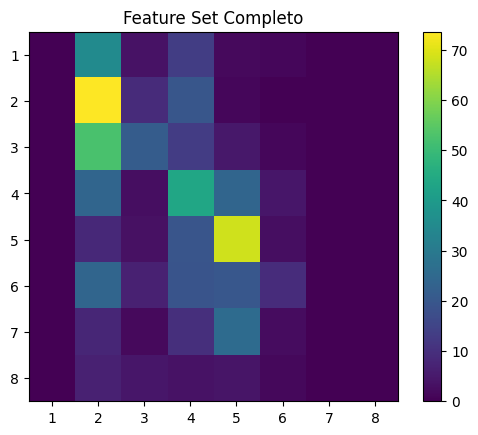

0.5563505268996117 --> 0.01823454885222497


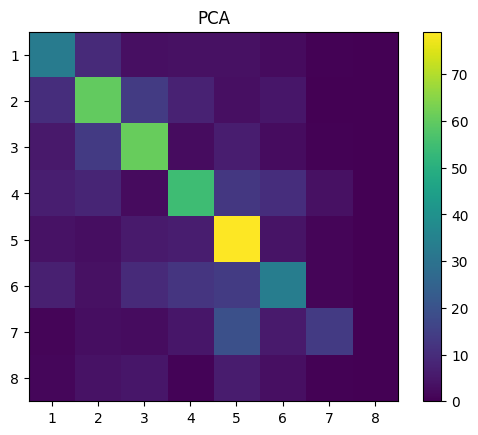

0.3245146977260122 --> 0.015100743962653018


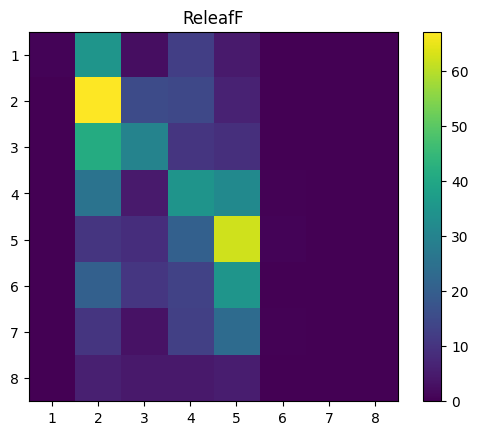

In [271]:
# 1) feature set completo
metricas,cm = tt_mean_std(extracted,emotions,0.7)
print(str(metricas["F1-Score"]["mean"]) + " --> " + str(metricas["F1-Score"]["std_dev"]))
plt.imshow(cm, cmap='viridis', interpolation='nearest')
plt.colorbar()
plt.title("Feature Set Completo")
plt.xticks(np.arange(8), np.arange(1, 9))
plt.yticks(np.arange(8), np.arange(1, 9))
plt.show()

# 2) features transformadas (PCA)
metricas_pca,cm = tt_mean_std(pca_fit(extracted)[1], emotions, 0.7)
print(str(metricas_pca["F1-Score"]["mean"]) + " --> " + str(metricas_pca["F1-Score"]["std_dev"]))
plt.imshow(cm, cmap='viridis', interpolation='nearest')
plt.colorbar()
plt.title("PCA")
plt.xticks(np.arange(8), np.arange(1, 9))
plt.yticks(np.arange(8), np.arange(1, 9))
plt.show()

frames = np.load('frames.npy')
extracted, emotions = add_features(frames)
# 3) features selecionadas (ReleafF)
metricas_releaff,cm = tt_mean_std(extracted[:,relieff],emotions,0.7)
print(str(metricas_releaff["F1-Score"]["mean"]) + " --> " + str(metricas_releaff["F1-Score"]["std_dev"]))
plt.imshow(cm, cmap='viridis', interpolation='nearest')
plt.colorbar()
plt.title("ReleafF")
plt.xticks(np.arange(8), np.arange(1, 9))
plt.yticks(np.arange(8), np.arange(1, 9))
plt.show()

## 2.1.2

In [266]:
def SVMloso(X,y):
    mets = []
    cms= []
    dicio = {}
    X_train,X_test,y_train,y_test = LOSO(extracted,emocoes,atores)
    for i in range(1,len(np.unique(actors))+1):
        svm = SVM(X_train[i],y_train[i])
        met,cm = metrics(svm,X_test[i],y_test[i])
        mets.append(met)
        mets.append(cm)
        cms.append(cm)
        for k, v in met.items():
            if k not in dicio:
                dicio[k] = {'values': [v], 'mean': v, 'std_dev': 0}
            else:
                dicio[k]['values'].append(v)
                dicio[k]['mean'] = np.mean(dicio[k]['values'])
                dicio[k]['std_dev'] = np.std(dicio[k]['values'])
    
    return dicio,np.mean(cms,axis=0)

extracted,atores,emocoes = actorsnonan(frames)

0.34980329089809925 --> 0.0956972889785143


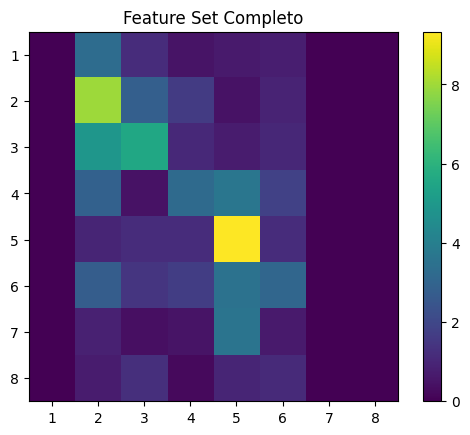

0.34980329089809925 --> 0.0956972889785143


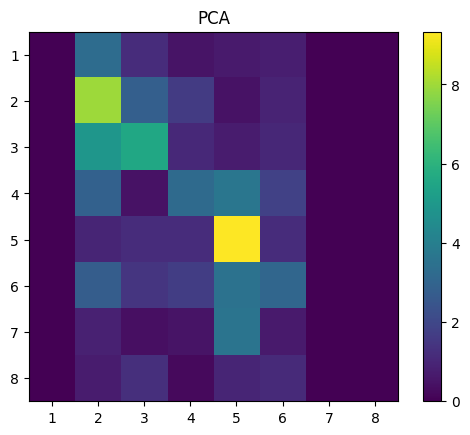

0.16179347299991778 --> 0.03254991430705824


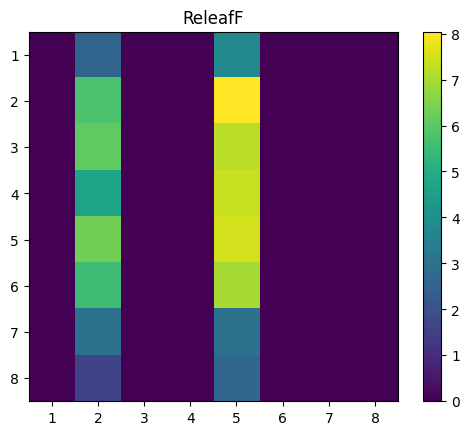

In [ ]:
# 1) feature set completo
metricas,cm = SVMloso(extracted,emotions)
print(str(metricas["F1-Score"]["mean"]) + " --> " + str(metricas["F1-Score"]["std_dev"]))
plt.imshow(cm, cmap='viridis', interpolation='nearest')
plt.colorbar()
plt.title("Feature Set Completo")
plt.xticks(np.arange(8), np.arange(1, 9))
plt.yticks(np.arange(8), np.arange(1, 9))
plt.show()

# 2) features transformadas (PCA)
metricas_pca,cm = SVMloso(pca_fit(extracted)[1], emotions)
print(str(metricas_pca["F1-Score"]["mean"]) + " --> " + str(metricas_pca["F1-Score"]["std_dev"]))
plt.imshow(cm, cmap='viridis', interpolation='nearest')
plt.colorbar()
plt.title("PCA")
plt.xticks(np.arange(8), np.arange(1, 9))
plt.yticks(np.arange(8), np.arange(1, 9))
plt.show()

frames = np.load('frames.npy')
extracted, emotions = add_features(frames)
# 3) features selecionadas (ReleafF)
metricas_releaff,cm = SVMloso(extracted[:,relieff],emotions)
print(str(metricas_releaff["F1-Score"]["mean"]) + " --> " + str(metricas_releaff["F1-Score"]["std_dev"]))
plt.imshow(cm, cmap='viridis', interpolation='nearest')
plt.colorbar()
plt.title("ReleafF")
plt.xticks(np.arange(8), np.arange(1, 9))
plt.yticks(np.arange(8), np.arange(1, 9))
plt.show()

# 3

## 3.1

In [247]:
data, emotions, actors = getData(type='3d')

def tresum(data,landmark,mode='abs'):
    array = np.zeros(shape = (len(data),round(len(data[0].T)/2)),dtype=np.float32)
    landmarks = landmark.split('_')
    posicao = int(landmarks[1])

    if landmarks[0] == 'y':
        posicao = posicao + 68
    fs = 30
    Ts = 1/fs
    
    if mode != 'abs':
        for i in range(len(data)):
            N = np.nan_to_num(data[i][posicao])
            y = rfft(N)
            array[i] = np.angle(y)
    else:
        for i in range(len(data)):
            N = np.nan_to_num(data[i][posicao])
            y = rfft(N)
            array[i] = np.abs(y)
    return array

dados = tresum(data,'x_54')

## 3.2

In [248]:
def tresdois(mode='abs'):
    fs = 30
    Ts = 1/fs
    freq = rfftfreq(len(data[0].T),Ts)
    
    if mode == 'angle':
        medidasx = [[0.157,1],[9,11],[13,15]]
        medidasy = [[-1,1],[-1,0.5],[-4,0]]
        for j in range(len(medidasx)):
            for i in np.unique(emotions):
                emotes = dados[np.where(emotions == i)]
                mu1 = np.abs(np.mean(emotes, axis=0))
                mu1 = np.log10(np.abs(mu1))
                sigma1 = np.log10(np.std(emotes, axis=0))
                plt.plot(freq, mu1, lw=2, label='emotion ' + str(i),)
                plt.fill_between(freq, mu1+sigma1, mu1-sigma1, alpha=0.1)
                plt.legend(bbox_to_anchor=(1.3, 0.5))
                plt.xlim(medidasx[j][0],medidasx[j][1])
                plt.ylim(medidasy[j][0],medidasy[j][1])
                plt.grid()
                plt.title("Média intervalo do Abs " + str(j+1))
            plt.show()
        for i in np.unique(emotions):
            emotes = dados[np.where(emotions == i)]
            mu1 = np.abs(np.std(emotes, axis=0))
            mu1 = np.log10(np.abs(mu1))
            sigma1 = np.log10(np.std(emotes, axis=0))
            plt.plot(freq, mu1, lw=2, label='emotion ' + str(i),)
            plt.fill_between(freq, mu1+sigma1, mu1-sigma1, alpha=0.1)
            plt.legend(bbox_to_anchor=(1.3, 0.5))
            plt.xlim(0,4)
            plt.ylim(-1,0.5)
            plt.title("Desvio Padrão Abs")
            plt.grid()
        plt.show()
        for i in np.unique(emotions):
            emotes = dados[np.where(emotions == i)]
            mu1 = np.abs(np.mean(emotes, axis=0))
            mu1 = np.log10(np.abs(mu1))
            sigma1 = np.log10(np.std(emotes, axis=0))
            plt.plot(freq, mu1, lw=2, label='emotion ' + str(i),)
            plt.fill_between(freq, mu1+sigma1, mu1-sigma1, alpha=0.1)
            plt.legend(bbox_to_anchor=(1.3, 0.5))
            plt.title("Média Abs, gráfico total")
            plt.grid()
        plt.show()
        for i in np.unique(emotions):
            emotes = dados[np.where(emotions == i)]
            mu1 = np.abs(np.std(emotes, axis=0))
            mu1 = np.log10(np.abs(mu1))
            sigma1 = np.log10(np.std(emotes, axis=0))
            plt.plot(freq, mu1, lw=2, label='emotion ' + str(i),)
            plt.fill_between(freq, mu1+sigma1, mu1-sigma1, alpha=0.1)
            plt.legend(bbox_to_anchor=(1.3, 0.5))

            plt.title("Desvio Padrão, Abs gráfico total")
            plt.grid()
        plt.show()
    else:
        for i in np.unique(emotions):
            emotes = dados[np.where(emotions == i)]
            mu1 = np.log10(np.mean(emotes, axis=0))
            sigma1 = np.log10(np.mean(emotes, axis=0))
            plt.plot(freq, mu1, lw=2, label='emotion ' + str(i),)
            plt.fill_between(freq, mu1+sigma1, mu1-sigma1, alpha=0.1)
            plt.legend(bbox_to_anchor=(1.3, 0.5))
            plt.xlim(0,1)
            plt.ylim(5,3)
            plt.grid()
            plt.title("Média Angle")
        plt.show()
        for i in np.unique(emotions):
            emotes = dados[np.where(emotions == i)]
            mu1 = np.log10(np.std(emotes, axis=0))
            sigma1 = np.log10(np.mean(emotes, axis=0))
            plt.plot(freq, mu1, lw=2, label='emotion ' + str(i),)
            plt.fill_between(freq, mu1+sigma1, mu1-sigma1, alpha=0.1)
            plt.legend(bbox_to_anchor=(1.3, 0.5))
            plt.xlim(0,1)
            plt.ylim(5,3)
            plt.title("Desvio Padrão Angle")
            plt.grid()
        plt.show()
        for i in np.unique(emotions):
            emotes = dados[np.where(emotions == i)]
            mu1 = np.log10(np.mean(emotes, axis=0))
            sigma1 = np.log10(np.mean(emotes, axis=0))
            plt.plot(freq, mu1, lw=2, label='emotion ' + str(i),)
            plt.fill_between(freq, mu1+sigma1, mu1-sigma1, alpha=0.1)
            plt.legend(bbox_to_anchor=(1.3, 0.5))
            plt.title("Média Angle, gráfico total")
            plt.grid()
        plt.show()
        for i in np.unique(emotions):
            emotes = dados[np.where(emotions == i)]
            mu1 = np.log10(np.std(emotes, axis=0))
            sigma1 = np.log10(np.mean(emotes, axis=0))
            plt.plot(freq, mu1, lw=2, label='emotion ' + str(i),)
            plt.fill_between(freq, mu1+sigma1, mu1-sigma1, alpha=0.1)
            plt.legend(bbox_to_anchor=(1.3, 0.5))
            plt.title("Desvio Padrão Angle, gráfico total")
            plt.grid()
    plt.show()

In [249]:
# Para o normal tirar este intervalo 0.          0.15706806  0.31413613  0.47120419  0.62827225  0.78534031 0.94240838
# Para o angulo 0.          0.15706806  0.31413613  0.47120419  0.62827225  0.78534031 0.94240838  1.09947644 
#8.95287958  9.10994764  9.26701571 9.42408377  9.58115183  9.7382199   9.89528796 10.05235602 10.20942408 10.36649215 10.52356021 10.68062827 10.83769634 10.9947644  11.15183246
# 12.87958115 13.03664921 13.19371728 13.35078534 13.5078534  13.66492147 13.82198953 13.97905759 14.13612565 14.29319372 14.45026178 14.60732984 14.76439791 14.92146597


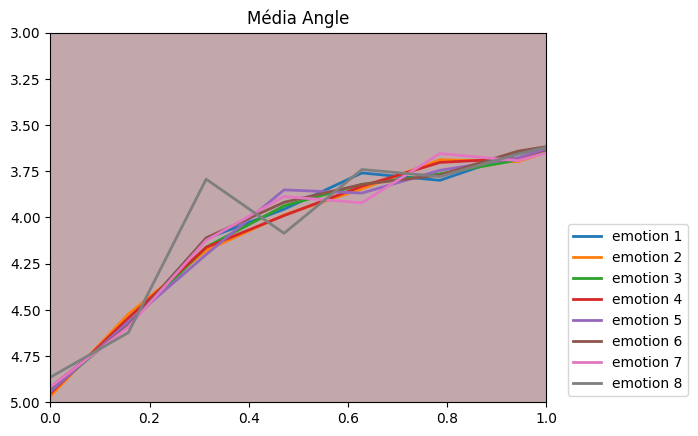

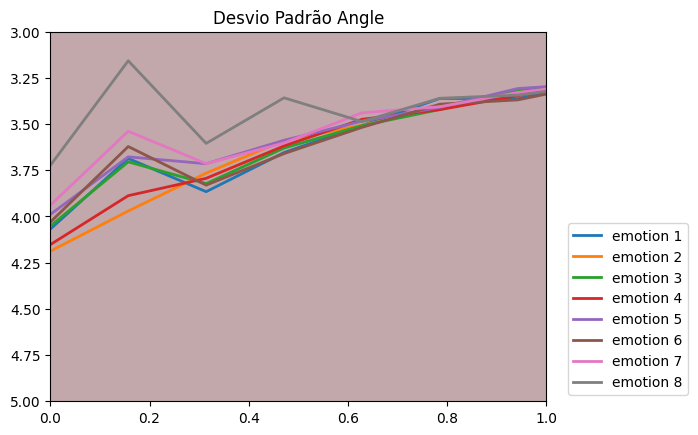

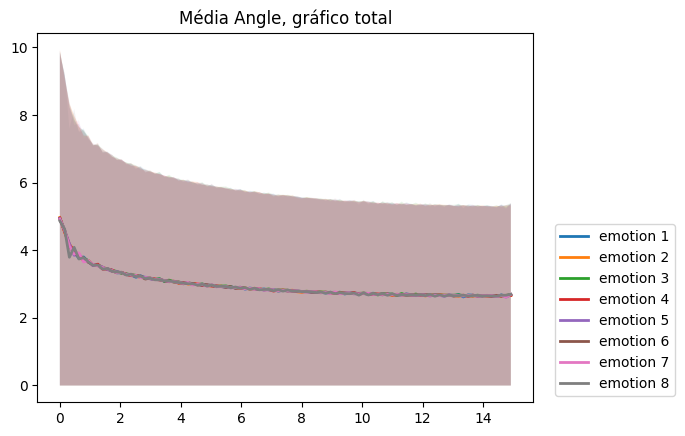

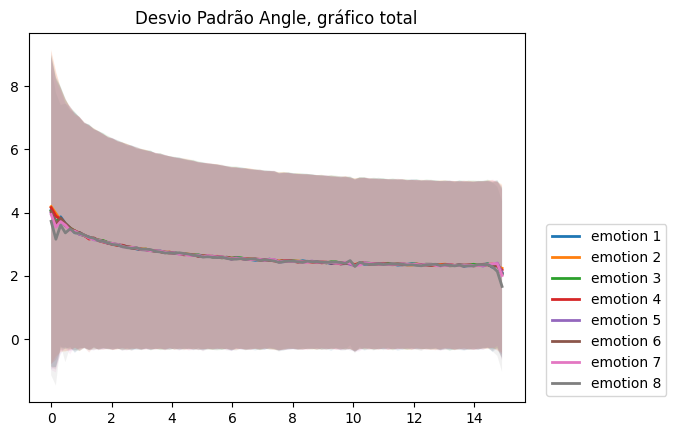

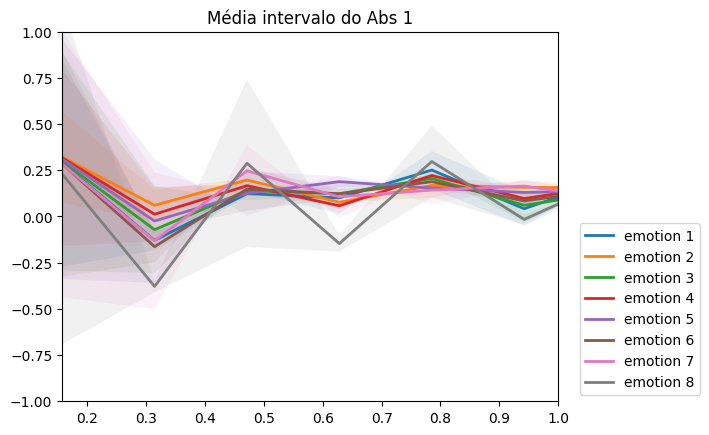

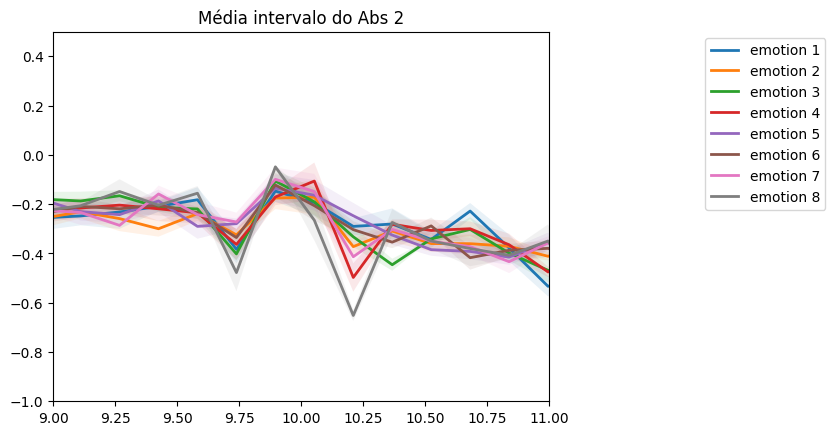

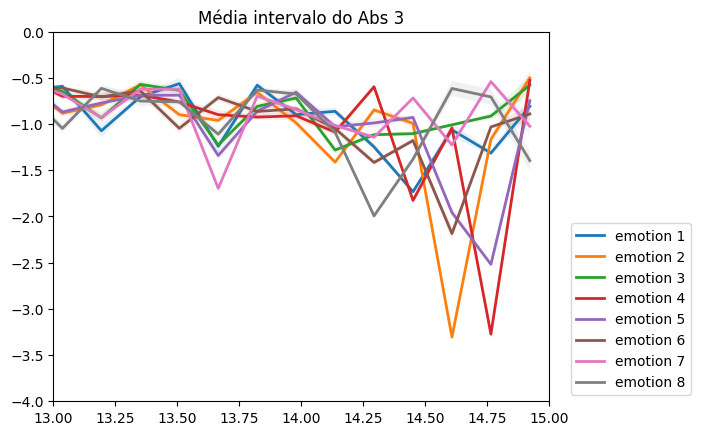

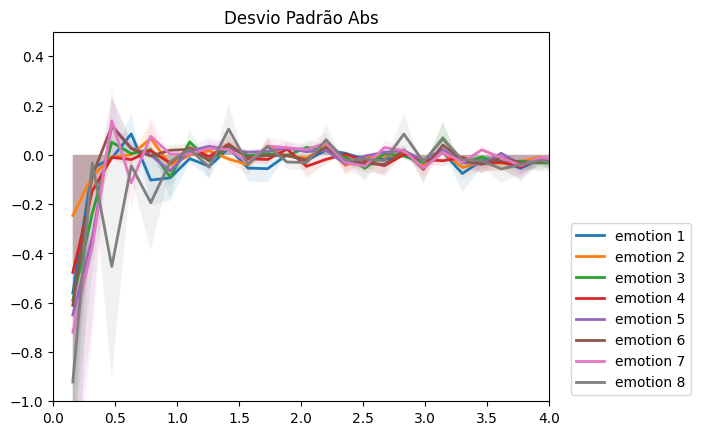

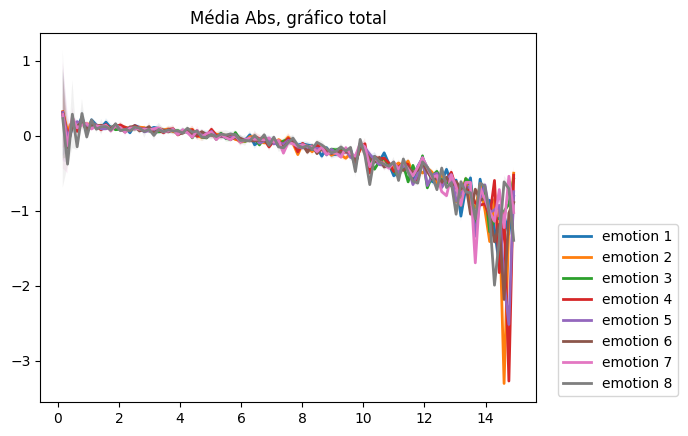

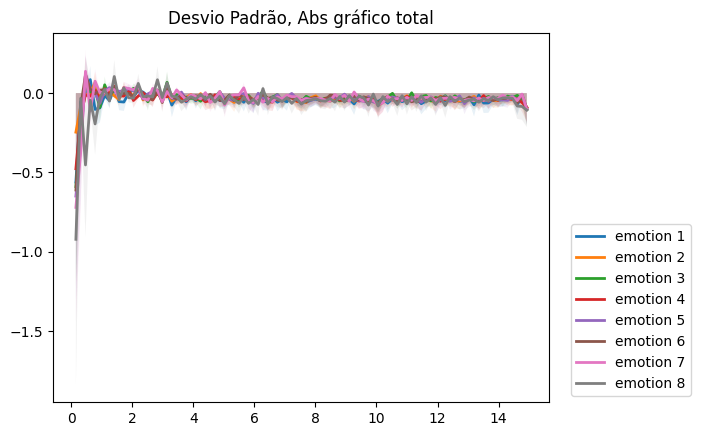

In [250]:
data, emotions, actors = getData(type='3d')
dados = tresum(data,'x_54')
tresdois()

data, emotions, actors = getData(type='3d')
dados = tresum(data,'x_54',mode='angle')
tresdois(mode = 'angle')

## 3.2.1

As diferenças ao longo do espectro não são muito nítidas, nem para a média do ângulo nem o desvio padrão. É observável que todas as emoções têm a mesma tendência de valores mas no início do espectro do desvio padrão é onde se nota mais diferença. Dentro dos resultados obtidos, decidimos aproximar a janela nos sítios onde se notava mais diferença para ver se observávamos algum ou alguns pontos que diferenciássem bem a diferença entre emoções, obtendo a diferença mais nítida no gráfico onde fazemos uma aproximação à média no intervalo das últimas frequências (Média intervalo do Abs 3).

## 3.2.2

In [251]:
data, emotions, actors = getData(type='3d')
dados = tresum(data,'x_54',mode='angle')

matrix = []

for i in np.unique(actors):
    data = dados[np.where(actors == i)]
    matrix_aux = []
    for e in np.unique(emotions):
        emotes = data[np.where(emotions[np.where(actors == i)] == e)]
        matrix_aux.append(np.mean(emotes, axis=0))
    matrix.append(matrix_aux)
        
matrix

[[array([ 0.        , -1.802364  , -0.13750017, -2.085872  , -0.568464  ,
         -1.1866801 , -1.7859567 , -1.6763004 , -0.73313814, -1.4308174 ,
         -1.192962  , -1.0673094 , -1.7025491 , -1.532562  , -0.59805685,
         -2.0145454 , -1.063236  , -1.2887905 , -1.5171872 , -1.3895342 ,
         -0.55778337, -1.8268181 , -0.93953246, -1.5722455 , -1.3883579 ,
         -1.2483678 , -1.0970628 , -1.7151521 , -0.7882037 , -1.0441251 ,
         -1.263006  , -1.0923408 , -0.96782494, -1.1938003 , -1.02352   ,
         -0.88635063, -1.1282554 , -0.91390187, -0.82773185, -0.7207111 ,
         -1.309131  , -0.3942775 , -0.9925841 , -0.8536809 , -0.71434563,
         -0.9021225 , -1.1562895 , -0.35723493, -1.2287401 , -0.7023769 ,
         -0.8649895 , -0.7775266 , -1.0097637 , -0.45117757, -1.0751697 ,
         -0.5659634 , -0.39126593, -0.5440953 , -0.4854663 , -0.6265124 ,
         -0.97202414, -0.44193593, -0.6360818 , -0.9641401 , -0.3430418 ,
         -0.49220246, -0.81973255, -0.

Realizmos a implementação só nesta alínea por atores uma vez que foi explicado pelo professor que não era necessário fazer esse passo intermédio, o que nos resultou numa matriz de valores médios demasiado extensa e teríamos de realizar demasiadas visualizações para as comparar o que seria impossível.

## 3.3.1

As features que selecionamos foram referentes tanto ao gráfico com o np.abs tanto com o np.ang. Usamos ambas as variantes para a visualização. Os gráficos mostram os intervalos em que as variações de emoção para emoção foram mais significativas. Notamos uma maior diferença de emoção para emoção no espectro da np.angle. As features que extraimos foram no gráfico da Média dos intervalos angle 3 nas frequências de 14.29319372, 14.60732984 e 14.76439791. Extraimos também uma feature na frequência 0.31413613 pois conseguimos facilmente distinguir a emoção 8 das restantes para uma melhor classficação por parte do nosso modelo. O objetivo inicial de extração de features era encontrar features em que conseguissemos distinguir principalmente as features 1,7 e 8 que eram aquelas que estavam a ser pior classificadas pelo nosso modelo ou frequências em que uma grande maioria das frequências fossem diferentes de umas para as outras para como nos instantes 14.29319372, 14.60732984 e 14.76439791, que conseguimos com mais clareza distinguir as emoções umas das outras.

## 3.3.2

In [272]:
def actorsdft(frames):
    atores = []
    land_x = [x+17 for x in range(10)]
    land_y = [x+68 for x in land_x]
    land = land_x +land_y
    features = []
    emotion = []
    
    eyes = [36,37,38,39,40,41,42,43,44,45,46,47]
    mouth = [60,61,62,63,64,65,66,67]
    mouth_ang = [57,48,51]
    eye_brow1 = [21,39,22,42]
    eye_brow2 = [19,37,24,44]

    for e in range(24):
        data3d, emotions, actors = getData(actor=e+1, type='3d')
        dataang = tresum(data3d,'x_54',mode='angle')
        for i in range(data3d.shape[0]):
            f_data =[]

            # Single video normalized
            video = data3d[i, :, :frames[i]].T
            data = normalizar(video)

            # Landmarks
            for l in land:
                f_data.append(float(np.mean(data[:,l])))                

            # Areas
            f_data.append(area_eyes(data, eyes))
            f_data.append(calculate_area(data, mouth))

            # Angles
            f_data.append(angle(data, mouth_ang))

            # Distances
            f_data.append(brow_dist(data, eye_brow1))
            f_data.append(brow_dist(data, eye_brow2))
            
            #Dft
            f_data.append(dataang[i][91])
            f_data.append(dataang[i][93])
            f_data.append(dataang[i][94])
            
            # Save
            if len(np.where(np.isnan(f_data))[0])==0:
                features.append(f_data)
                atores.append(e+1)
                emotion.append(emotions[i])
    return np.array(features),np.array(atores),np.array(emotion)

0.23269134950741907 --> 0.04757922571850133


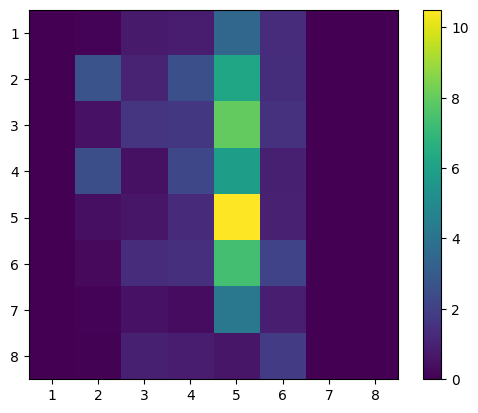

In [276]:
frames = np.load('frames.npy')
extracted,actors, emotions = actorsdft(frames)

X_train,X_test,y_train,y_test = LOSO(extracted,emotions,actors)

metricas,cm = SVMloso(extracted, emotions)

print(str(metricas["F1-Score"]["mean"]) + " --> " + str(metricas["F1-Score"]["std_dev"]))
plt.imshow(cm, cmap='viridis', interpolation='nearest')
plt.colorbar()
plt.xticks(np.arange(8), np.arange(1, 9))
plt.yticks(np.arange(8), np.arange(1, 9))
plt.show()

# 4

In [277]:
def quatroum(data):
    fs = 30
    tempomin = min(frames)*1/fs
    signal_len = int(tempomin * fs) 
    posicao = 54
    
    array = []
    
    for i in range(len(data)):
        signal = data[i][posicao][:signal_len]
        f, t, Zxx = stft(signal, fs=fs, window='hann',nperseg=50,noverlap=40)
        #Valor baixo de nperseg vai dar uma alta resolução temporal enquanto que o contrário dá uma alta resolução de frequência
        tf = np.abs(Zxx)
        tf_norm= np.zeros_like(tf)
        for w in range(tf.shape[0]):
            tf_norm[w,:] = (tf[w,:] - np.mean(tf[w,:])) / np.mean(tf[w,:])
        array.append(tf_norm)
    
    return f,t,np.array(array)

In [278]:
data, emotions, actors = getData(type='3d')

normalizar(data)

f,t,tresd = quatroum(data)

In [280]:
def quatrodoisdois(dados):
    fs = 30
    tempomin = min(frames)*1/fs
    signal_len = int(tempomin * fs) 
    
    for i in np.unique(emotions):
        emotes = dados[np.where(emotions == i)]
        signal = np.std(np.nan_to_num(data[np.where(emotions == i)]),axis=0)
        signal = signal[54][:signal_len]
        med = np.std(emotes, axis=0)
        plt.pcolormesh(t,f,med)
        plt.plot(np.linspace(0, tempomin, signal_len),signal*500,'r')
        plt.xlim(0,tempomin)
        plt.show()

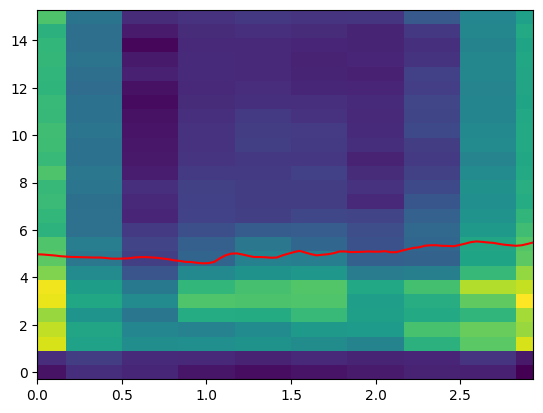

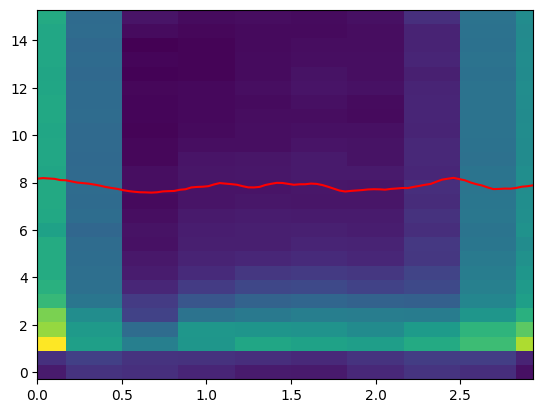

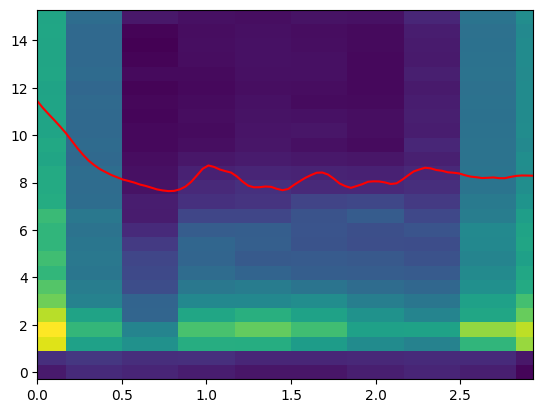

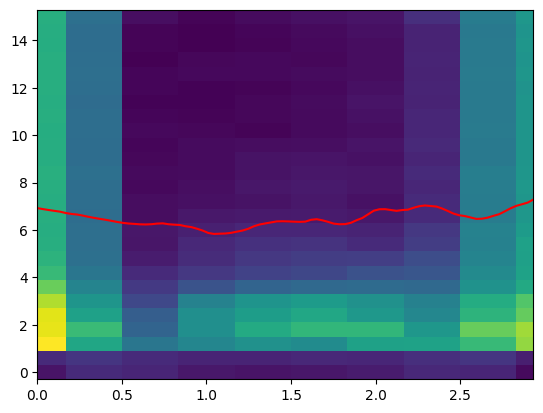

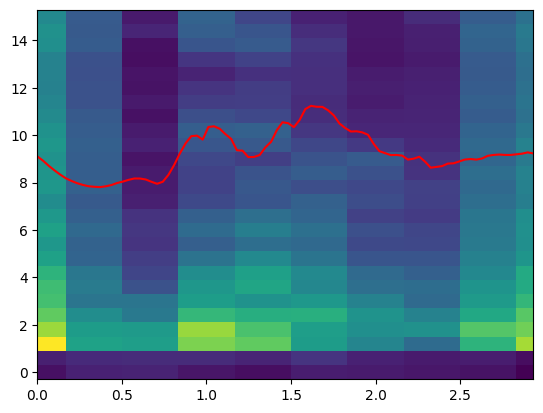

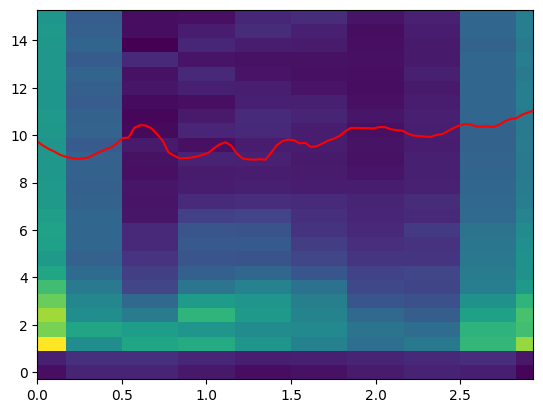

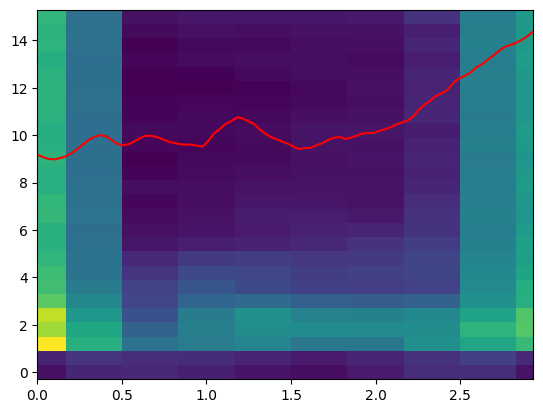

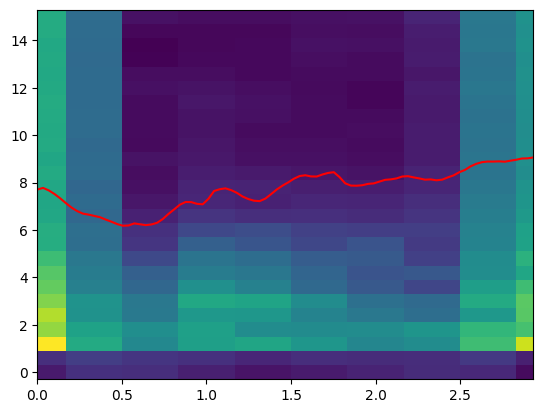

In [281]:
quatrodoisdois(tresd)

Observamos nesta análise que as emoções, mais uma vez, seguem a mesma tendência, é apenas observável pequenas diferenças entre a emoções.
A primeira emoção distingue-se mais pelas menores frequências após os 2.5s segundos com valores altos, enquanto que a segunda emoção pelos baixos valores entre os 0.7s e 2.5s. Na emoção 3 não há nada que se realce dos outros e a emoção 4 parece uma mistura da 2 e da 3. A emoção 5 têm uns valores altos nas frequências baixas entre os 1s e 1.5s. A emoção 6 e 8 são bastante parecidas. E a sétima também não se nota grande diferença para as outras.

In [282]:
data, emotions, actors = getData(type='3d')
dados = tresum(data,'x_54',mode='angle')

matrix = []

for i in np.unique(actors):
    data = dados[np.where(actors == i)]
    matrix_aux = []
    for e in np.unique(emotions):
        signal = np.mean(np.nan_to_num(data[np.where(emotions[np.where(actors == i)] == e)]),axis=0)
        signal = signal[:88]
    matrix.append(signal)
        
matrix

[array([ 0.        , -1.6419512 , -0.40854493, -1.7947562 , -0.23876613,
        -1.9117151 , -0.50971335, -2.076453  , -0.62658983, -1.5029081 ,
        -0.7835968 , -1.6335753 , -0.94395   , -1.3954551 , -1.0459244 ,
        -1.1007994 , -1.2320486 , -1.2490433 , -0.60522527, -1.0795376 ,
        -0.9645334 , -1.2032669 , -0.90719587, -1.3671144 , -0.6526122 ,
        -1.50066   , -0.80289465, -1.6728251 , -0.945445  , -1.3821304 ,
        -0.714505  , -1.2127361 , -0.8413893 , -1.347051  , -1.0005639 ,
        -1.1047162 , -0.7846132 , -1.2484362 , -0.5168668 , -1.3889334 ,
        -0.5785244 , -1.5420816 , -0.47150728, -1.687844  , -0.60037106,
        -1.4496245 , -0.36101574, -1.1836817 , -0.51863295, -1.3285141 ,
        -0.66741776, -1.1525904 , -0.8101707 , -0.9170868 , -0.9716215 ,
        -1.0431433 , -0.7146961 , -0.8050276 , -0.86093295, -0.9322874 ,
        -0.53992754, -1.0534194 , -0.41889313, -1.1645305 , -0.5490386 ,
         0.08824772, -0.6909977 , -0.03260008, -0.4

Realizmos a implementação só nesta alínea por atores uma vez que foi explicado pelo professor que não era necessário fazer esse passo intermédio, o que nos resultou numa matriz de valores médios demasiado extensa e teríamos de realizar demasiadas visualizações para as comparar o que seria impossível.

In [283]:
def actorsstft(frames):
    atores = []
    land_x = [x+17 for x in range(10)]
    land_y = [x+68 for x in land_x]
    land = land_x +land_y
    features = []
    emotion = []
    
    eyes = [36,37,38,39,40,41,42,43,44,45,46,47]
    mouth = [60,61,62,63,64,65,66,67]
    mouth_ang = [57,48,51]
    eye_brow1 = [21,39,22,42]
    eye_brow2 = [19,37,24,44]

    for e in range(24):
        data3d, emotions, actors = getData(actor=e+1, type='3d')
        dataang = tresum(data3d,'x_54',mode='angle')
        f,t,tresd = quatroum(data3d)
        for i in range(data3d.shape[0]):
            f_data =[]

            # Single video normalized
            video = data3d[i, :, :frames[i]].T
            data = normalizar(video)

            # Landmarks
            for l in land:
                f_data.append(float(np.mean(data[:,l])))                

            # Areas
            f_data.append(area_eyes(data, eyes))
            f_data.append(calculate_area(data, mouth))

            # Angles
            f_data.append(angle(data, mouth_ang))

            # Distances
            f_data.append(brow_dist(data, eye_brow1))
            f_data.append(brow_dist(data, eye_brow2))
            
            #Dft
            f_data.append(dataang[i][91])
            f_data.append(dataang[i][93])
            f_data.append(dataang[i][94])
            
            #stft
            f_data.append(tresd[i][6][8])
            f_data.append(tresd[i][3][3])
            # Save
            if len(np.where(np.isnan(f_data))[0])==0:
                features.append(f_data)
                atores.append(e+1)
                emotion.append(emotions[i])
    return np.array(features),np.array(atores),np.array(emotion)

0.2308082069579326 --> 0.04502942873386508


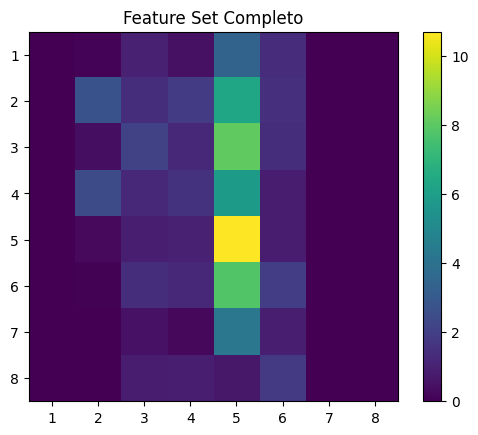

In [285]:
data, emotions, actors = getData(type='3d')

frames = np.load('frames.npy')
extracted,actors,emotions = actorsstft(frames)

X_train,X_test,y_train,y_test = LOSO(extracted,emotions,actors)

metricas,cm = SVMloso(extracted, emotions)

print(str(metricas["F1-Score"]["mean"]) + " --> " + str(metricas["F1-Score"]["std_dev"]))
plt.imshow(cm, cmap='viridis', interpolation='nearest')
plt.colorbar()
plt.title("Feature Set Completo")
plt.xticks(np.arange(8), np.arange(1, 9))
plt.yticks(np.arange(8), np.arange(1, 9))
plt.show()

No caso do sinal Stft(Short term fourier Transform) os parâmetros escolhidos foi a janela de hann, um valor de nperseg de 50 e um overlap de 4/5 do valor de nperseg sendo este 40. Um valor mais baixo de nperseg vai nos dar uma alta resolução temporal enquanto que o contrário vai nos dar uma alta resolução de frequência mas baixa resolução temporal. Neste caso o nosso intervalo temporal vai estar dividido em 9 intervalos e na resolução de frequência vamos ter 25 intervalos. A primeira feature que escolhemos foi nas frequências entre as frequências de 3.6 e 4.2 no tempo de 2.667 a 3. Retiramos esta feature pois a variação nas matrizes tempo-frequência conseguimos ver que a variação vai ser maior na emoção 1 comparativamente com as outras emoções todas, uma emoção que tinha sido classificada pelo nosso modelo. A segunda feature foi retirada entre as frequências de 1.8 e 2.4 e o tempo entre 1 e 1.33. Esta feature foi retirada após comparação com todas as outras emoções e constatamos que eram aí os valores que mais variavam de emoção para emoção. É de notar que utilizamos para o sinal o desvio padrão pois após testarmos vários parâmetros nas stfts com a média não conseguimos encontrar nenhum intervalo que conseguissemos notar uma variação de emoção para emoção. É também importante frisar que o sinal a vermelho é o sinal médio por emoção.

# 5

## 5.1

In [296]:
def actorsdft(frames):
    land_x = [x+17 for x in range(10)]
    land_y = [x+68 for x in land_x]
    land = land_x +land_y
    features = []
    emotion = []
    
    eyes = [36,37,38,39,40,41,42,43,44,45,46,47]
    mouth = [60,61,62,63,64,65,66,67]
    mouth_ang = [57,48,51]
    eye_brow1 = [21,39,22,42]
    eye_brow2 = [19,37,24,44]

    for e in range(8):
        data3d, emotions, actors = getData(emotion=e+1, type='3d')
        dataang = tresum(data3d,'x_54',mode='angle')
        for i in range(data3d.shape[0]):
            f_data =[]

            # Single video normalized
            video = data3d[i, :, :frames[i]].T
            data = normalizar(video)

            # Landmarks
            for l in land:
                f_data.append(float(np.mean(data[:,l])))                

            # Areas
            f_data.append(area_eyes(data, eyes))
            f_data.append(calculate_area(data, mouth))

            # Angles
            f_data.append(angle(data, mouth_ang))

            # Distances
            f_data.append(brow_dist(data, eye_brow1))
            f_data.append(brow_dist(data, eye_brow2))
            
            f_data.append(dataang[i][2])
            f_data.append(dataang[i][91])
            f_data.append(dataang[i][93])
            f_data.append(dataang[i][94])
            
            #stft
            f_data.append(tresd[i][6][8])
            f_data.append(tresd[i][3][3])
            
            # Save
            if len(np.where(np.isnan(f_data))[0])==0:
                features.append(f_data)
                
                # Emotion
                emotion.append(e+1)
                
                
    return np.array(features), np.array(emotion)


## 5.2

In [297]:
data, emotions, actors = getData(type='3d')

frames = np.load('frames.npy')
extracted,actors,emotions = actorsstft(frames)

sha_result = shapiro_test(extracted)

X_train,X_test,y_train,y_test = LOSO(extracted,emocoes,atores)

results = parametric(extracted, emotions, sha_result)

for i in range(len(results)):
    if results[i] == 1:
        print("Feature",i+1, ": Significant")
    else:
        print("Feature",i+1, ": Non Significant")

Feature 1 : Non Significant
Feature 2 : Non Significant
Feature 3 : Non Significant
Feature 4 : Non Significant
Feature 5 : Non Significant
Feature 6 : Non Significant
Feature 7 : Non Significant
Feature 8 : Non Significant
Feature 9 : Non Significant
Feature 10 : Non Significant
Feature 11 : Non Significant
Feature 12 : Non Significant
Feature 13 : Non Significant
Feature 14 : Non Significant
Feature 15 : Non Significant
Feature 16 : Non Significant
Feature 17 : Non Significant
Feature 18 : Non Significant
Feature 19 : Non Significant
Feature 20 : Non Significant
Feature 21 : Non Significant
Feature 22 : Non Significant
Feature 23 : Non Significant
Feature 24 : Non Significant
Feature 25 : Non Significant
Feature 26 : Non Significant
Feature 27 : Non Significant
Feature 28 : Non Significant
Feature 29 : Non Significant
Feature 30 : Non Significant


*Não percebemos porque é que aqui dão todos não significantes, mesmo as features recolhidas na meta anterior

Para explicar 75.0 % do feature set, devemos usar 1 variáveis.


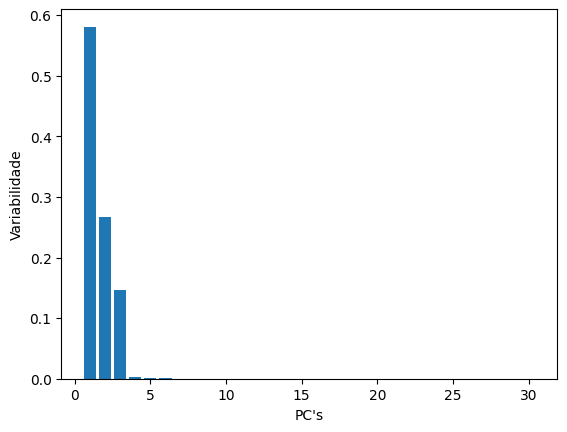

In [298]:
percentagem = 0.75
var, n_pc = pca_analyses(extracted, percentagem)

print("Para explicar", percentagem*100,"% do feature set, devemos usar", n_pc,"variáveis.") 

plt.bar(range(1,len(var)+1), var)
plt.xlabel("PC's")
plt.ylabel("Variabilidade")
plt.show()

In [299]:
fisherscore = FisherScore(extracted,emotions,mode='dtft')

print("10 melhores features de acordo com o FisherScore: " + str(fisherscore))

relieff = reliefF(extracted,emotions)

print("10 melhores features de acordo com o ReliefF: " + str(relieff))

instante = 0
fs = extracted[instante, fisherscore] 
print("Features do instante", instante, "para o Fisher Score:", fs)

rf = extracted[instante, relieff]
print("Features do instante", instante, "para o ReliefF:", rf)

10 melhores features de acordo com o FisherScore: [ 0 27 26 25 24 23 22 21 20 19]
10 melhores features de acordo com o ReliefF: [29 24 23 26 22 21 20  9  8 27]
Features do instante 0 para o Fisher Score: [-0.09895887  0.80884039 -0.71146768 -0.66630054  0.00619499  0.00520185
  0.09315351  0.07517635  0.04414975 -0.03236394]
Features do instante 0 para o ReliefF: [-0.96125621  0.00619499  0.00520185 -0.71146768  0.09315351  0.07517635
  0.04414975  0.10518815  0.08915259  0.80884039]


0.3607321131447587 --> 0.022415883793392804


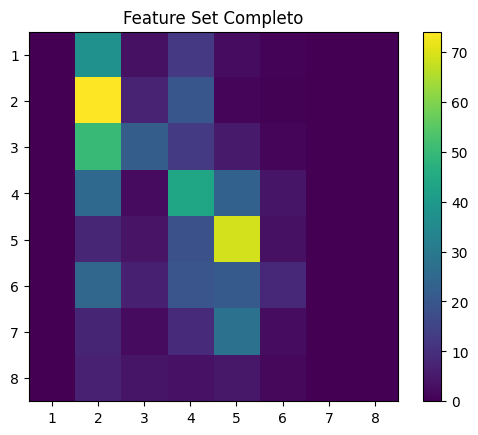

0.5585690515806988 --> 0.012445137461426297


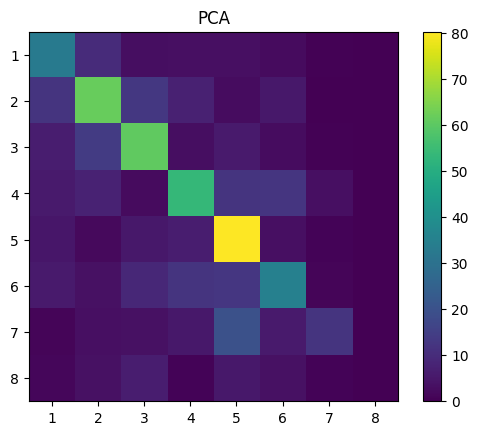

0.20654464780920684 --> 0.013819556901014995


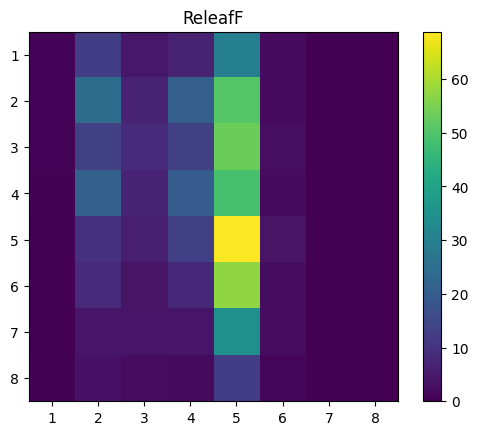

In [303]:
# 1) feature set completo
metricas,cm = tt_mean_std(extracted,emotions,0.7)
print(str(metricas["F1-Score"]["mean"]) + " --> " + str(metricas["F1-Score"]["std_dev"]))
plt.imshow(cm, cmap='viridis', interpolation='nearest')
plt.colorbar()
plt.title("Feature Set Completo")
plt.xticks(np.arange(8), np.arange(1, 9))
plt.yticks(np.arange(8), np.arange(1, 9))
plt.show()

# 2) features transformadas (PCA)
metricas_pca,cm = tt_mean_std(pca_fit(extracted)[1], emotions, 0.7)
print(str(metricas_pca["F1-Score"]["mean"]) + " --> " + str(metricas_pca["F1-Score"]["std_dev"]))
plt.imshow(cm, cmap='viridis', interpolation='nearest')
plt.colorbar()
plt.title("PCA")
plt.xticks(np.arange(8), np.arange(1, 9))
plt.yticks(np.arange(8), np.arange(1, 9))
plt.show()

frames = np.load('frames.npy')
extracted, emotions = actorsdft(frames)
# 3) features selecionadas (ReleafF)
metricas_releaff,cm = tt_mean_std(extracted[:,relieff],emotions,0.7)
print(str(metricas_releaff["F1-Score"]["mean"]) + " --> " + str(metricas_releaff["F1-Score"]["std_dev"]))
plt.imshow(cm, cmap='viridis', interpolation='nearest')
plt.colorbar()
plt.title("ReleafF")
plt.xticks(np.arange(8), np.arange(1, 9))
plt.yticks(np.arange(8), np.arange(1, 9))
plt.show()

0.2308082069579326 --> 0.04502942873386508


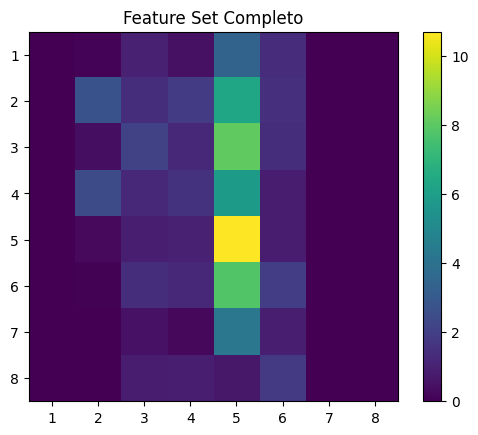

0.2308082069579326 --> 0.04502942873386508


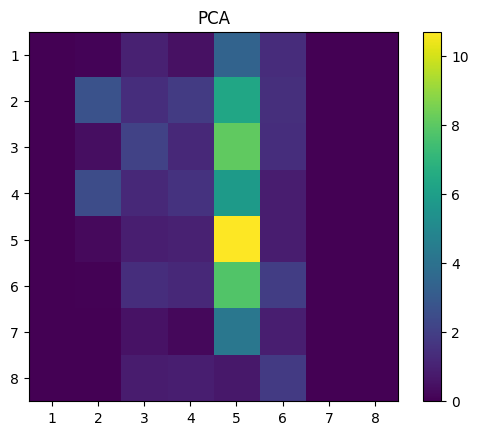

0.1756061336066329 --> 0.0367038485581965


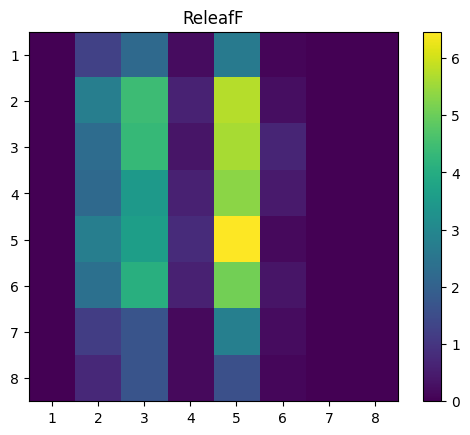

In [301]:
# 1) feature set completo
metricas,cm = SVMloso(extracted,emotions)
print(str(metricas["F1-Score"]["mean"]) + " --> " + str(metricas["F1-Score"]["std_dev"]))
plt.imshow(cm, cmap='viridis', interpolation='nearest')
plt.colorbar()
plt.title("Feature Set Completo")
plt.xticks(np.arange(8), np.arange(1, 9))
plt.yticks(np.arange(8), np.arange(1, 9))
plt.show()

# 2) features transformadas (PCA)
metricas_pca,cm = SVMloso(pca_fit(extracted)[1], emotions)
print(str(metricas_pca["F1-Score"]["mean"]) + " --> " + str(metricas_pca["F1-Score"]["std_dev"]))
plt.imshow(cm, cmap='viridis', interpolation='nearest')
plt.colorbar()
plt.title("PCA")
plt.xticks(np.arange(8), np.arange(1, 9))
plt.yticks(np.arange(8), np.arange(1, 9))
plt.show()

frames = np.load('frames.npy')
extracted, emotions = actorsdft(frames)
# 3) features selecionadas (ReleafF)
metricas_releaff,cm = SVMloso(extracted[:,relieff],emotions)
print(str(metricas_releaff["F1-Score"]["mean"]) + " --> " + str(metricas_releaff["F1-Score"]["std_dev"]))
plt.imshow(cm, cmap='viridis', interpolation='nearest')
plt.colorbar()
plt.title("ReleafF")
plt.xticks(np.arange(8), np.arange(1, 9))
plt.yticks(np.arange(8), np.arange(1, 9))
plt.show()

## 5.3

Os nossos resultados, no geral, com as novas features pioraram. Com o feature set completo e com reliefF pioraram os resultados uma vez que os seus valores de F1-Score reduziram. Em relação ao pca, deixamos de ter duas componentes para explicar maior parte dos dados e passamos a ter só uma. 
A abordagem realizada de frequência e tempo-frequência, em princípio foram bem percebidas e aplicadas, no entanto algum bug deve-nos ter atrabalhado, pois agora na segunda meta todas as features nos deram não significativas e não percebemos porquê. Uma razão que também nos pode ter feito piorar os resultados.